# Лабораторная работа №17: Diffusion model с нуля и classifier-free guidance

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать forward noising и noise prediction.
- Обучить compact conditional network.
- Добавить CFG и сравнить guidance scales.

## Теоретическая часть

DDPM постепенно добавляет Gaussian noise, затем обучает network обращать процесс. Classifier-free guidance смешивает conditional и unconditional predictions и управляет компромиссом fidelity/diversity.

![DDPM](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/ddpm.png)


DDPM обучает εθ(x_t,t,y) восстанавливать внесённый шум. При classifier-free dropout условие заменяется специальным индексом 10; на inference ε_cfg=ε_u+w(ε_c−ε_u). Для MNIST качество класса проверяет отдельно обученный на train классификатор, его точность на test обязательно сообщается.

Прямой процесс: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. CFG: $\hat\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$; при двух вызовах сети на шаг $\mathrm{NFE}=2T$.

### Экспериментальный протокол

Данные MNIST: train первые 20 000, test первые 2 000, без пересечения. Полное обучение: 10 000 шагов; smoke: 2. Основной результат — реальные MNIST checkpoint и условная генерация при разных w. Для продолжения после сбоя сохраняйте artifacts в Drive или задайте CV_ARTIFACTS. Не смешивайте smoke/full checkpoint.

### Материалы

- [DDPM paper](https://arxiv.org/abs/2006.11239)
- [Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True: только проверка связности, не для сдачи

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка: artifacts/lab17 — метрики, рисунки, checkpoints
# (ddpm.pt, classifier.pt, classifier_validation.json потом читает lab 18);
# smoke пишет в artifacts/lab17/smoke, чтобы не смешивать smoke/full checkpoint.
# data/lab17 — зафиксированный split; MNIST общий и уже лежит в data/MNIST/raw.
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab17'))
if FAST_DEV_RUN:
    ARTIFACTS = ARTIFACTS / 'smoke'
DATA_ROOT = Path(os.getenv('CV_DATA', 'data/lab17'))
MNIST_ROOT = Path(os.getenv('CV_MNIST', 'data'))
CKPT_DIR = ARTIFACTS / 'checkpoints'
FIG_DIR = ARTIFACTS / 'figures'
for folder in (ARTIFACTS, DATA_ROOT, CKPT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Протокол: MNIST train первые 20 000 / test первые 2 000, 10 000 шагов обучения;
# сокращённый режим — 2 шага и малое число timesteps T
N_TRAIN = 512 if FAST_DEV_RUN else 20_000
N_TEST = 256 if FAST_DEV_RUN else 2_000
TRAIN_STEPS = 2 if FAST_DEV_RUN else 10_000
T_STEPS = 50 if FAST_DEV_RUN else 1000
NULL_CLASS = 10       # индекс «без условия» для classifier-free dropout
P_UNCOND = 0.1        # доля батча, у которой условие заменяется на NULL_CLASS
GUIDANCE_SCALES = [0.0, 1.0, 2.0, 4.0, 7.0]  # 0 — безусловная, 1 — условная, >1 — CFG
SAMPLES_PER_CLASS = 2 if FAST_DEV_RUN else 10
NOTEBOOK_T0 = time.time()  # начало прогона — для итогового run_info.json

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
    destination.write_text(text, encoding='utf-8')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS),
       'data': str(DATA_ROOT), 'mnist': str(MNIST_ROOT),
       'n_train': N_TRAIN, 'n_test': N_TEST, 'steps': TRAIN_STEPS, 'T': T_STEPS,
       'guidance_scales': GUIDANCE_SCALES, 'samples_per_class': SAMPLES_PER_CLASS})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab17', 'data': 'data\\lab17', 'mnist': 'data', 'n_train': 20000, 'n_test': 2000, 'steps': 10000, 'T': 1000, 'guidance_scales': [0.0, 1.0, 2.0, 4.0, 7.0], 'samples_per_class': 10}


### Задание 1. Расписание прямой диффузии

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума.

**Результат.** Проверяемое состояние «Расписание прямой диффузии» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума» и его результат доступен следующему этапу.

**Расписание прямой диффузии**

- **Что делали**: задали линейное расписание β_t от 1e-4 до 0.02 на T = 1000 шагов, из него α_t = 1 − β_t и ᾱ_t (произведение α). Написали `q_sample`, которая сразу зашумляет картинку до шага t по формуле x_t = √ᾱ_t·x₀ + √(1−ᾱ_t)·ε с шумом, переданным снаружи. Проверили формулу вручную, восстановили шум обратно из x_t и сравнили среднее и дисперсию x_t с теорией.
- **Зачем**: расписание определяет, сколько шума на каждом шаге; от него зависят обучение и генерация. Ошибку здесь нельзя было бы увидеть по итоговым метрикам.
- **Результат**: schedule.json и schedule.png. ᾱ_T = 4.0e-5, сигнал в x_T всего √ᾱ_T = 0.006, то есть последний шаг — практически чистый шум. Ошибка формулы 0.0, шум восстанавливается с точностью 5e-6, среднее и дисперсия x_t совпали с теорией (0.1394 vs 0.1395, 0.9222 vs 0.9222). Все проверки ✔.

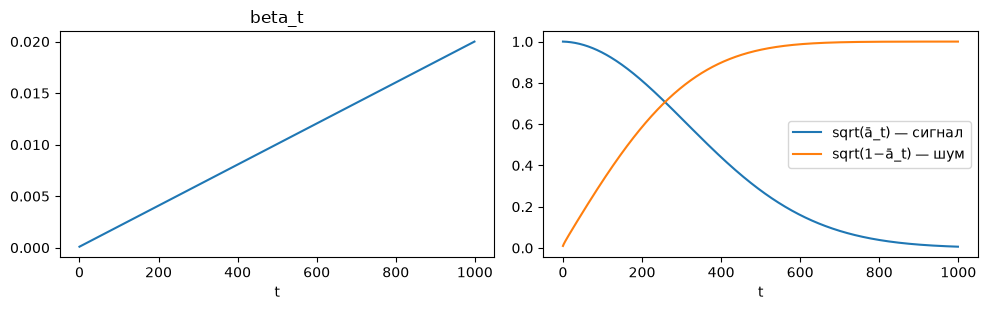

{'T': 1000, 'beta[0]': 9.999999747378752e-05, 'beta[T-1]': 0.019999999552965164, 'alpha_bar_T': 4.0358296246267855e-05, 'signal_coef_T': 0.006352818105369806, 'formula_err': 0.0, 'recover_err': 4.76837158203125e-06, 'marginal': (0.1394, 0.1395, 0.9222, 0.9222)}


In [2]:
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt

BETA_START, BETA_END = 1e-4, 0.02


def diffusion_schedule(T, beta_start=BETA_START, beta_end=BETA_END):
    """Линейный beta-schedule DDPM (Ho et al., 2020). Границы растягиваются в 1000/T раз,
    чтобы при малом T (smoke) alpha_bar_T тоже был близок к нулю, как при T=1000."""
    scale = 1000 / T
    betas = torch.linspace(beta_start * scale, beta_end * scale, T, dtype=torch.float64)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, 0)
    alpha_bars_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bars[:-1]])
    posterior_var = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)  # beta_tilde_t
    sched = {'betas': betas, 'alphas': alphas, 'alpha_bars': alpha_bars,
             'alpha_bars_prev': alpha_bars_prev, 'posterior_var': posterior_var}
    return {k: v.float() for k, v in sched.items()}


def q_sample(x0, t, noise, sched):
    """x_t = sqrt(ā_t)·x0 + sqrt(1 − ā_t)·ε, шум ε передаётся снаружи (его же предсказывает сеть)."""
    ab = sched['alpha_bars'].to(x0.device)[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise


SCHED = diffusion_schedule(T_STEPS)
SCHEDULE_CONFIG = {'type': 'linear, scaled by 1000/T', 'T': T_STEPS,
                   'beta_start': BETA_START * 1000 / T_STEPS, 'beta_end': BETA_END * 1000 / T_STEPS}
betas, alphas, alpha_bars = SCHED['betas'], SCHED['alphas'], SCHED['alpha_bars']

# --- Проверки расписания ---
assert betas.shape == (T_STEPS,) and bool(((betas > 0) & (betas < 1)).all())
assert bool((betas[1:] > betas[:-1]).all()), 'beta должна возрастать'
assert torch.allclose(alphas, 1 - betas)
manual_ab, running = [], 1.0
for a in alphas.double().tolist():  # alpha_bar как явное произведение
    running *= a
    manual_ab.append(running)
assert torch.allclose(alpha_bars.double(), torch.tensor(manual_ab, dtype=torch.float64), rtol=1e-5)
assert bool((alpha_bars[1:] < alpha_bars[:-1]).all())

# --- Проверка формулы с внешним шумом ---
check_gen = torch.Generator().manual_seed(SEED)
x0_chk = torch.rand((6, 1, 28, 28), generator=check_gen) * 2 - 1
eps_chk = torch.randn((6, 1, 28, 28), generator=check_gen)
t_chk = torch.tensor([0, 1, T_STEPS // 4, T_STEPS // 2, 3 * T_STEPS // 4, T_STEPS - 1])
xt_chk = q_sample(x0_chk, t_chk, eps_chk, SCHED)
ab_chk = alpha_bars[t_chk].view(-1, 1, 1, 1)
manual_xt = torch.sqrt(ab_chk) * x0_chk + torch.sqrt(1 - ab_chk) * eps_chk
recovered_eps = (xt_chk - ab_chk.sqrt() * x0_chk) / (1 - ab_chk).sqrt()
formula_err = (xt_chk - manual_xt).abs().max().item()
recover_err = (recovered_eps - eps_chk).abs().max().item()
assert formula_err < 1e-6 and recover_err < 1e-4, (formula_err, recover_err)
assert torch.equal(q_sample(x0_chk, t_chk, eps_chk, SCHED), xt_chk), 'q_sample должен быть детерминирован при фиксированном шуме'

# Маргинальное распределение q(x_t | x0) для константного x0: mean = sqrt(ā)x0, var = 1 − ā
t_mid = T_STEPS // 2
big_eps = torch.randn((20_000, 1, 28, 28), generator=check_gen)
xt_big = q_sample(torch.full_like(big_eps, 0.5), torch.full((len(big_eps),), t_mid), big_eps, SCHED)
emp_mean, emp_var = xt_big.mean().item(), xt_big.var().item()
th_mean, th_var = 0.5 * alpha_bars[t_mid].sqrt().item(), 1 - alpha_bars[t_mid].item()
assert abs(emp_mean - th_mean) < 5e-3 and abs(emp_var - th_var) < 5e-3, (emp_mean, th_mean, emp_var, th_var)
del big_eps, xt_big

probe_t = sorted({0, T_STEPS // 10, T_STEPS // 4, T_STEPS // 2, 3 * T_STEPS // 4, T_STEPS - 1})
schedule_report = {
    **SCHEDULE_CONFIG,
    'alpha_bar_T': alpha_bars[-1].item(),
    'signal_coef_T': alpha_bars[-1].sqrt().item(),   # остаточный сигнал в x_T
    'snr_T': (alpha_bars[-1] / (1 - alpha_bars[-1])).item(),
    'by_t': [{'t': t, 'beta': betas[t].item(), 'alpha_bar': alpha_bars[t].item(),
              'sqrt_alpha_bar': alpha_bars[t].sqrt().item(), 'sqrt_one_minus_alpha_bar': (1 - alpha_bars[t]).sqrt().item()}
             for t in probe_t],
    'checks': {'formula_max_abs_err': formula_err, 'recovered_noise_max_abs_err': recover_err,
               f'marginal_t{t_mid}': {'emp_mean': emp_mean, 'th_mean': th_mean, 'emp_var': emp_var, 'th_var': th_var}},
}
save_json('schedule.json', schedule_report)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(betas.numpy()); ax[0].set_title('beta_t'); ax[0].set_xlabel('t')
ax[1].plot(alpha_bars.sqrt().numpy(), label='sqrt(ā_t) — сигнал')
ax[1].plot((1 - alpha_bars).sqrt().numpy(), label='sqrt(1−ā_t) — шум')
ax[1].set_xlabel('t'); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / 'schedule.png', dpi=120); plt.show()

print({'T': T_STEPS, 'beta[0]': betas[0].item(), 'beta[T-1]': betas[-1].item(),
       'alpha_bar_T': schedule_report['alpha_bar_T'], 'signal_coef_T': schedule_report['signal_coef_T'],
       'formula_err': formula_err, 'recover_err': recover_err,
       'marginal': (round(emp_mean, 4), round(th_mean, 4), round(emp_var, 4), round(th_var, 4))})

### Задание 2. Условный denoiser и проверка форм

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода.

**Результат.** Проверяемое состояние «Условный denoiser и проверка форм» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода» и его результат доступен следующему этапу.

**Условный denoiser**

- **Что делали**: собрали компактный U-Net (нейросеть ищет шум на картинке. Подается номер шага t и подсказкой класс у если известен) `TinyDenoiser` 28→14→7→14→28 с ResBlock-ами, self-attention в середине и skip-соединениями. Номер шага t (sinusoidal embedding + MLP) и класс y (embedding на 11 значений: цифры 0–9 и 10 = «без условия») подмешиваются в каждый блок. Прогнали 4 случайные картинки и записали формы на каждом этапе.
- **Зачем**: сеть должна по (x_t, t, y) предсказывать шум той же формы, что вход, и реально учитывать t и y — иначе не будет ни обучения, ни CFG.
- **Результат**: denoiser_shapes.json. 2 329 409 параметров, выход (4, 1, 28, 28) = форма входа. Выход зависит от класса (разница 0.65) и от t (0.018 для соседних шагов), градиенты доходят до embedding класса. Все проверки ✔.

In [3]:
import copy
import torch.nn as nn


def timestep_embedding(t, dim):
    """Sinusoidal embedding номера шага (как позиционное кодирование Transformer)."""
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    """GroupNorm → SiLU → Conv, embedding (время + класс) добавляется как сдвиг по каналам."""

    def __init__(self, c_in, c_out, emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(emb_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.drop = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    """Глобальное внимание на карте 7×7 (49 позиций) в середине U-Net."""

    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        s = self.norm(x).flatten(2).transpose(1, 2)
        out, _ = self.attn(s, s, s, need_weights=False)
        return x + out.transpose(1, 2).reshape(b, c, h, w)


class TinyDenoiser(nn.Module):
    """Compact U-Net 28→14→7→14→28: предсказывает ε по (x_t, t, y); y=10 — безусловная ветвь CFG."""

    def __init__(self, base=64, mults=(1, 2, 2), num_classes=10, emb_dim=256, dropout=0.1):
        super().__init__()
        self.config = {'base': base, 'mults': list(mults), 'num_classes': num_classes,
                       'emb_dim': emb_dim, 'dropout': dropout}
        self.null_class = num_classes
        c1, c2, c3 = (base * m for m in mults)
        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)  # +1 — null-условие
        self.inp = nn.Conv2d(1, c1, 3, padding=1)
        self.down1 = ResBlock(c1, c1, emb_dim, dropout)
        self.ds1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)            # 28 → 14
        self.down2 = ResBlock(c1, c2, emb_dim, dropout)
        self.ds2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)            # 14 → 7
        self.mid1 = ResBlock(c2, c3, emb_dim, dropout)
        self.attn = SelfAttention(c3)
        self.mid2 = ResBlock(c3, c3, emb_dim, dropout)
        self.us2 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(c3, c3, 3, padding=1))  # 7 → 14
        self.up2 = ResBlock(c3 + c2, c2, emb_dim, dropout)
        self.us1 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(c2, c2, 3, padding=1))  # 14 → 28
        self.up1 = ResBlock(c2 + c1, c1, emb_dim, dropout)
        self.out = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)  # на старте ε̂ = 0: стабильное начало обучения
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.config['base'])) + self.class_emb(y)
        h1 = self.down1(self.inp(x), emb)
        h2 = self.down2(self.ds1(h1), emb)
        h = self.mid2(self.attn(self.mid1(self.ds2(h2), emb)), emb)
        h = self.up2(torch.cat([self.us2(h), h2], 1), emb)
        h = self.up1(torch.cat([self.us1(h), h1], 1), emb)
        return self.out(h)


# --- Проверка форм на каждом этапе ---
torch.manual_seed(SEED)
denoiser_check = TinyDenoiser().to(DEVICE).eval()
stage_shapes = {}
stage_names = ['inp', 'down1', 'ds1', 'down2', 'ds2', 'mid1', 'attn', 'mid2', 'us2', 'up2', 'us1', 'up1', 'out']
hooks = [getattr(denoiser_check, n).register_forward_hook(
    lambda m, i, o, n=n: stage_shapes.__setitem__(n, list(o.shape))) for n in stage_names]
x_chk = torch.randn(4, 1, 28, 28, device=DEVICE)
t_chk = torch.tensor([0, T_STEPS // 3, 2 * T_STEPS // 3, T_STEPS - 1], device=DEVICE)
y_chk = torch.tensor([0, 3, 7, NULL_CLASS], device=DEVICE)
with torch.no_grad():
    out_chk = denoiser_check(x_chk, t_chk, y_chk)
for h in hooks:
    h.remove()
assert out_chk.shape == x_chk.shape, out_chk.shape
assert out_chk.abs().max().item() == 0.0, 'zero-init выхода'
assert stage_shapes['ds2'][-2:] == [7, 7] and stage_shapes['up1'][-2:] == [28, 28]

# Зависимость от условия и времени: копия со случайным выходным слоем
probe = copy.deepcopy(denoiser_check).eval()
nn.init.normal_(probe.out[-1].weight, std=0.02)
with torch.no_grad():
    base_out = probe(x_chk, t_chk, y_chk)
    null_out = probe(x_chk, t_chk, torch.full_like(y_chk, NULL_CLASS))
    shift_out = probe(x_chk, (t_chk + 1).clamp(max=T_STEPS - 1), y_chk)
class_effect = (base_out - null_out)[:3].abs().max().item()  # первые три — реальные классы
time_effect = (base_out - shift_out)[:3].abs().max().item()
assert class_effect > 0 and time_effect > 0
probe.train()
probe(x_chk, t_chk, y_chk).pow(2).mean().backward()
grad_ok = {n: getattr(probe, n).weight.grad is not None and getattr(probe, n).weight.grad.abs().sum().item() > 0
           for n in ['class_emb', 'inp']}
assert all(grad_ok.values()), grad_ok
n_params = sum(p.numel() for p in denoiser_check.parameters())
del probe

save_json('denoiser_shapes.json', {'config': denoiser_check.config, 'n_params': n_params,
                                   'input': list(x_chk.shape), 'output': list(out_chk.shape),
                                   'stage_shapes': stage_shapes, 'class_effect': class_effect,
                                   'time_effect': time_effect, 'grads_reach_embeddings': grad_ok})
print({'params': n_params, 'out': tuple(out_chk.shape), 'class_effect': class_effect, 'time_effect': time_effect})
for n in stage_names:
    print(f'{n:6s}', stage_shapes[n])
del denoiser_check

{'params': 2329409, 'out': (4, 1, 28, 28), 'class_effect': 0.6487864851951599, 'time_effect': 0.018197476863861084}
inp    [4, 64, 28, 28]
down1  [4, 64, 28, 28]
ds1    [4, 64, 14, 14]
down2  [4, 128, 14, 14]
ds2    [4, 128, 7, 7]
mid1   [4, 128, 7, 7]
attn   [4, 128, 7, 7]
mid2   [4, 128, 7, 7]
us2    [4, 128, 14, 14]
up2    [4, 128, 14, 14]
us1    [4, 128, 28, 28]
up1    [4, 64, 28, 28]
out    [4, 1, 28, 28]


### Задание 3. Train/test MNIST для DDPM

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите фиксированный непересекающийся split и DataLoader.

**Результат.** Проверяемое состояние «Train/test MNIST для DDPM» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите фиксированный непересекающийся split и DataLoader» и его результат доступен следующему этапу.

**Train/test MNIST**

- **Что делали**: взяли первые 20 000 картинок официального train и первые 2 000 официального test, проверили хэшами отсутствие одинаковых картинок, перевели пиксели в [-1, 1]. Сделали DataLoader (батч 128, перемешивание с фиксированным seed). Зашумили 8 реальных цифр на разных t и измерили остаточный сигнал.
- **Зачем**: фиксированный непересекающийся split — основа честной оценки; DataLoader подаёт данные в обучение.
- **Результат**: split.json, data/lab17/mnist_split.pt, forward_noising.png. Дубликатов 0, классы сбалансированы (от 1775 до 2281 картинок на цифру в train), 156 батчей на эпоху. Корреляция x_t с цифрой падает от 0.9999 (t = 0) до 0.54 (t = 250), 0.18 (t = 500) и 0.02 (t = 999).

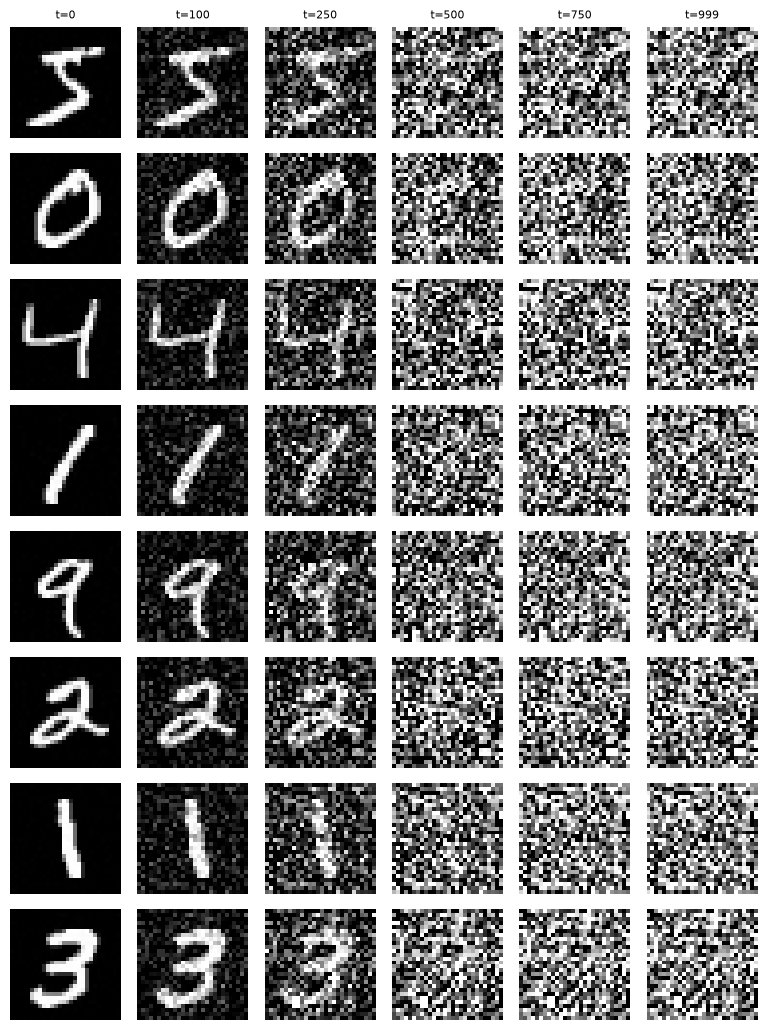

train (20000, 1, 28, 28) test (2000, 1, 28, 28) duplicates 0
train classes [1994, 2281, 1929, 2076, 1945, 1775, 1971, 2093, 1922, 2014]
test classes  [175, 234, 219, 207, 217, 179, 178, 205, 192, 194]
batches/epoch 156
{'t': 0, 'sqrt_alpha_bar': 0.9999499917030334, 'corr_xt_x0': 0.999862015247345}
{'t': 100, 'sqrt_alpha_bar': 0.9461192488670349, 'corr_xt_x0': 0.8699797987937927}
{'t': 250, 'sqrt_alpha_bar': 0.7220962643623352, 'corr_xt_x0': 0.5385802388191223}
{'t': 500, 'sqrt_alpha_bar': 0.2789205312728882, 'corr_xt_x0': 0.18461987376213074}
{'t': 750, 'sqrt_alpha_bar': 0.057447005063295364, 'corr_xt_x0': 0.048252347856760025}
{'t': 999, 'sqrt_alpha_bar': 0.006352818105369806, 'corr_xt_x0': 0.017636984586715698}


In [4]:
import hashlib
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset

# --- Реальные данные: первые N_TRAIN официального train и первые N_TEST официального test ---
mnist_train = datasets.MNIST(MNIST_ROOT, train=True, download=False)
mnist_test = datasets.MNIST(MNIST_ROOT, train=False, download=False)


def to_model_range(u8):
    """uint8 → [-1, 1]: та же шкала, что у стандартного шума N(0, I)."""
    return u8.unsqueeze(1).float() / 127.5 - 1.0


train_idx = torch.arange(N_TRAIN)
test_idx = torch.arange(N_TEST)
# Непересечение: разные официальные файлы + проверка на точные дубликаты пикселей
train_hashes = {hashlib.md5(img.numpy().tobytes()).hexdigest() for img in mnist_train.data[train_idx]}
dup_mask = torch.tensor([hashlib.md5(img.numpy().tobytes()).hexdigest() in train_hashes
                         for img in mnist_test.data[test_idx]])
n_duplicates = int(dup_mask.sum())
test_idx = test_idx[~dup_mask]  # дубликаты (если найдутся) исключаются из test

X_train = to_model_range(mnist_train.data[train_idx]); y_train = mnist_train.targets[train_idx].clone()
X_test = to_model_range(mnist_test.data[test_idx]); y_test = mnist_test.targets[test_idx].clone()
assert X_train.shape[1:] == (1, 28, 28) and X_train.min() >= -1 and X_train.max() <= 1

BATCH_SIZE = 64 if FAST_DEV_RUN else 128
loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=True, generator=loader_gen, num_workers=0,
                          pin_memory=DEVICE == 'cuda')
xb, yb = next(iter(train_loader))
assert xb.shape == (BATCH_SIZE, 1, 28, 28) and yb.shape == (BATCH_SIZE,)
loader_gen.manual_seed(SEED)  # пробный батч не сдвигает порядок обучения

train_counts = torch.bincount(y_train, minlength=10).tolist()
test_counts = torch.bincount(y_test, minlength=10).tolist()
torch.save({'X_train_u8': mnist_train.data[train_idx], 'y_train': y_train,
            'X_test_u8': mnist_test.data[test_idx], 'y_test': y_test,
            'train_indices': train_idx, 'test_indices': test_idx}, DATA_ROOT / 'mnist_split.pt')
save_json('split.json', {'source': 'torchvision MNIST (LeCun, Cortes, Burges), CC BY-SA 3.0',
                         'rule': 'first N of official train / first N of official test',
                         'n_train': len(train_idx), 'n_test': len(test_idx),
                         'train_range': [0, N_TRAIN - 1], 'test_range': [0, N_TEST - 1],
                         'exact_pixel_duplicates_removed_from_test': n_duplicates,
                         'train_class_counts': train_counts, 'test_class_counts': test_counts,
                         'pixel_range': [-1.0, 1.0], 'batch_size': BATCH_SIZE,
                         'batches_per_epoch': len(train_loader), 'loader_seed': SEED})

# --- Прямой процесс на реальных картинках: сколько сигнала остаётся в x_t ---
vis_t = sorted({0, T_STEPS // 10, T_STEPS // 4, T_STEPS // 2, 3 * T_STEPS // 4, T_STEPS - 1})
vis_x = X_train[:8]
vis_noise = torch.randn(vis_x.shape, generator=torch.Generator().manual_seed(SEED + 3))
residual = []
fig, axes = plt.subplots(len(vis_x), len(vis_t), figsize=(1.3 * len(vis_t), 1.3 * len(vis_x)))
for j, t_val in enumerate(vis_t):
    xt = q_sample(vis_x, torch.full((len(vis_x),), t_val), vis_noise, SCHED)
    corr = torch.corrcoef(torch.stack([xt.flatten(), vis_x.flatten()]))[0, 1].item()
    residual.append({'t': t_val, 'sqrt_alpha_bar': alpha_bars[t_val].sqrt().item(), 'corr_xt_x0': corr})
    for i in range(len(vis_x)):
        axes[i, j].imshow(xt[i, 0].clamp(-1, 1), cmap='gray', vmin=-1, vmax=1); axes[i, j].axis('off')
    axes[0, j].set_title(f't={t_val}', fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'forward_noising.png', dpi=110); plt.show()
save_json('forward_noising_real.json', residual)

print('train', tuple(X_train.shape), 'test', tuple(X_test.shape), 'duplicates', n_duplicates)
print('train classes', train_counts)
print('test classes ', test_counts)
print('batches/epoch', len(train_loader))
for r in residual:
    print(r)

### Задание 4. Обучение epsilon-предсказателя с CFG dropout

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора.

**Результат.** Проверяемое состояние «Обучение epsilon-предсказателя с CFG dropout» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора» и его результат доступен следующему этапу.

**Обучение с CFG dropout**

- **Что делали**: 10 000 шагов обучали сеть предсказывать шум (MSE между ε̂ и ε), t для каждой картинки случайный. У 10% картинок батча класс заменялся на 10 («без условия»), поэтому обе ветви учились одновременно. AdamW lr 2e-4 с разогревом, EMA-копия весов. Каждые 1000 шагов — checkpoint с весами, оптимизатором и генераторами для продолжения после сбоя.<br>
Передаем в нейросеть зашумленную картинку со случайным уровнем шума, t и класс. Сеть предсказывает шум. Мы сравниваем ошибку между шумом предсказанным нейросетью и нашим.
- **Зачем**: получить денойзер, который умеет работать и с подсказкой класса, и без неё — обе ветви нужны для classifier-free guidance.
- **Результат**: ddpm.pt (для lab 18), checkpoints/ddpm_last.pt, training_log.csv, training_loss.png. 13.1 мин на GPU. Loss упал с 0.030 (шаг 1000) до 0.022; в конце cond 0.0223, uncond 0.0232. Безусловная ветвь увидела 128 211 примеров из 1.28 млн (10.0%).

{'step': 1000, 'loss': 0.0298, 'cond_loss': 0.02959, 'uncond_loss': 0.03171, 'cond_n': 11508, 'uncond_n': 1292, 'lr': 0.0002, 'grad_norm': 0.11461} 81s
{'step': 2000, 'loss': 0.02615, 'cond_loss': 0.02624, 'uncond_loss': 0.02536, 'cond_n': 11535, 'uncond_n': 1265, 'lr': 0.0002, 'grad_norm': 0.17571} 160s
{'step': 3000, 'loss': 0.02483, 'cond_loss': 0.02464, 'uncond_loss': 0.02656, 'cond_n': 11484, 'uncond_n': 1316, 'lr': 0.0002, 'grad_norm': 0.21105} 239s
{'step': 4000, 'loss': 0.024, 'cond_loss': 0.02389, 'uncond_loss': 0.02499, 'cond_n': 11520, 'uncond_n': 1280, 'lr': 0.0002, 'grad_norm': 0.09349} 318s
{'step': 5000, 'loss': 0.02397, 'cond_loss': 0.02384, 'uncond_loss': 0.02516, 'cond_n': 11564, 'uncond_n': 1236, 'lr': 0.0002, 'grad_norm': 0.32396} 396s
{'step': 6000, 'loss': 0.0235, 'cond_loss': 0.02342, 'uncond_loss': 0.0243, 'cond_n': 11568, 'uncond_n': 1232, 'lr': 0.0002, 'grad_norm': 0.12279} 475s
{'step': 7000, 'loss': 0.02281, 'cond_loss': 0.02287, 'uncond_loss': 0.02227, 'con

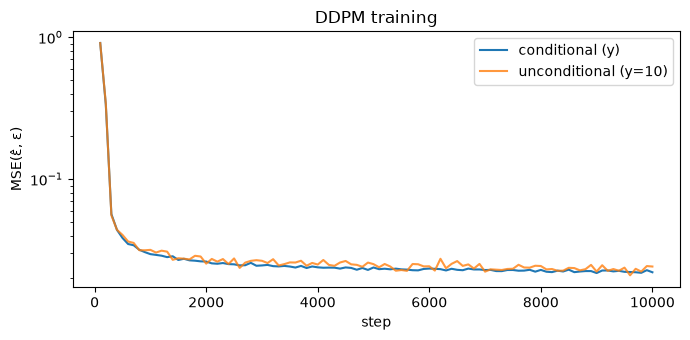

{'steps': 10000, 'train_seconds': 788.0353374481201, 'final_loss': 0.022433513344265518, 'final_cond_loss': 0.022347224217655774, 'final_uncond_loss': 0.023209368048667734, 'cond_samples_seen': 1151789, 'uncond_samples_seen': 128211}


In [5]:
import csv

LR = 2e-4
WARMUP_STEPS = 1 if FAST_DEV_RUN else 500
EMA_DECAY = 0.999       # для сэмплирования используются EMA-веса
GRAD_CLIP = 1.0
LOG_EVERY = 1 if FAST_DEV_RUN else 100
PRINT_EVERY = 1 if FAST_DEV_RUN else 1000
CKPT_EVERY = 1 if FAST_DEV_RUN else 1000
RUN_TAG = 'smoke' if FAST_DEV_RUN else 'full'
LAST_CKPT = CKPT_DIR / 'ddpm_last.pt'   # для возобновления после сбоя
DDPM_PATH = ARTIFACTS / 'ddpm.pt'       # итоговый checkpoint для lab 18
SCHED_DEV = {k: v.to(DEVICE) for k, v in SCHED.items()}
TRAIN_CONFIG = {'steps': TRAIN_STEPS, 'batch_size': BATCH_SIZE, 'lr': LR, 'warmup_steps': WARMUP_STEPS,
                'optimizer': 'AdamW(wd=0)', 'ema_decay': EMA_DECAY, 'grad_clip': GRAD_CLIP,
                'p_uncond': P_UNCOND, 'null_class': NULL_CLASS, 'loss': 'MSE(eps_hat, eps)',
                't_sampling': 'uniform{0..T-1}', 'seed': SEED, 'n_train': len(X_train)}

torch.manual_seed(SEED)
model = TinyDenoiser().to(DEVICE)
ema = copy.deepcopy(model).eval().requires_grad_(False)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
lr_sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS))
step_gen = torch.Generator(device=DEVICE).manual_seed(SEED + 1)  # t, ε и CFG dropout
history, start_step, train_seconds = [], 0, 0.0


def ddpm_state(step):
    return {'run_tag': RUN_TAG, 'step': step, 'model': model.state_dict(), 'ema': ema.state_dict(),
            'optimizer': opt.state_dict(), 'lr_scheduler': lr_sched.state_dict(),
            'model_config': model.config, 'schedule': SCHEDULE_CONFIG, 'train_config': TRAIN_CONFIG,
            'null_class': NULL_CLASS, 'history': history, 'train_seconds': train_seconds,
            'rng': {'torch': torch.get_rng_state(), 'step_gen': step_gen.get_state(),
                    'loader_gen': loader_gen.get_state()}}


if LAST_CKPT.exists():
    ck = torch.load(LAST_CKPT, map_location='cpu', weights_only=False)
    assert ck['run_tag'] == RUN_TAG, f"checkpoint режима {ck['run_tag']}, а сейчас {RUN_TAG}"
    assert ck['schedule'] == SCHEDULE_CONFIG and ck['model_config'] == model.config, 'другая конфигурация'
    model.load_state_dict(ck['model']); ema.load_state_dict(ck['ema'])
    opt.load_state_dict(ck['optimizer']); lr_sched.load_state_dict(ck['lr_scheduler'])
    step_gen.set_state(ck['rng']['step_gen']); loader_gen.set_state(ck['rng']['loader_gen'])
    torch.set_rng_state(ck['rng']['torch'])
    history, start_step, train_seconds = ck['history'], ck['step'], ck['train_seconds']
    print(f'resume from step {start_step}')  # порядок батчей после resume начинается с новой эпохи


def infinite_batches():
    while True:
        yield from train_loader


@torch.no_grad()
def ema_update():
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.lerp_(pm, 1 - EMA_DECAY)


model.train()
batches = infinite_batches()
acc = {'loss': 0.0, 'steps': 0, 'cond_sum': 0.0, 'cond_n': 0, 'uncond_sum': 0.0, 'uncond_n': 0}
seconds_before, t_start = train_seconds, time.time()
for step in range(start_step + 1, TRAIN_STEPS + 1):
    xb, yb = next(batches)
    x0 = xb.to(DEVICE, non_blocking=True); y = yb.to(DEVICE, non_blocking=True)
    b = x0.shape[0]
    t = torch.randint(0, T_STEPS, (b,), device=DEVICE, generator=step_gen)
    noise = torch.randn(x0.shape, device=DEVICE, generator=step_gen)
    drop = torch.rand(b, device=DEVICE, generator=step_gen) < P_UNCOND
    y_in = torch.where(drop, torch.full_like(y, NULL_CLASS), y)  # CFG dropout: обе ветви в одном батче
    per_sample = (model(q_sample(x0, t, noise, SCHED_DEV), t, y_in) - noise).pow(2).mean((1, 2, 3))
    loss = per_sample.mean()
    opt.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    opt.step(); lr_sched.step(); ema_update()

    acc['loss'] += loss.item(); acc['steps'] += 1
    acc['cond_sum'] += per_sample[~drop].sum().item(); acc['cond_n'] += int((~drop).sum())
    acc['uncond_sum'] += per_sample[drop].sum().item(); acc['uncond_n'] += int(drop.sum())
    if step % LOG_EVERY == 0 or step == TRAIN_STEPS:
        row = {'step': step, 'loss': acc['loss'] / acc['steps'],
               'cond_loss': acc['cond_sum'] / max(acc['cond_n'], 1),
               'uncond_loss': acc['uncond_sum'] / acc['uncond_n'] if acc['uncond_n'] else float('nan'),
               'cond_n': acc['cond_n'], 'uncond_n': acc['uncond_n'],
               'lr': lr_sched.get_last_lr()[0], 'grad_norm': float(grad_norm)}
        history.append(row)
        acc = {k: 0 for k in acc}
        if step % PRINT_EVERY == 0 or step == TRAIN_STEPS:
            print({k: round(v, 5) if isinstance(v, float) else v for k, v in row.items()},
                  f'{seconds_before + time.time() - t_start:.0f}s')
    if step % CKPT_EVERY == 0 or step == TRAIN_STEPS:
        train_seconds = seconds_before + time.time() - t_start
        torch.save(ddpm_state(step), LAST_CKPT)

final_ck = torch.load(LAST_CKPT, map_location='cpu', weights_only=False)
assert final_ck['step'] == TRAIN_STEPS and final_ck['run_tag'] == RUN_TAG
model.load_state_dict(final_ck['model']); ema.load_state_dict(final_ck['ema'])
history, train_seconds = final_ck['history'], final_ck['train_seconds']
ema.eval()

# Итоговый checkpoint: 'model' — EMA-веса для сэмплирования, плюс сырые веса и состояние оптимизатора
torch.save({'run_tag': RUN_TAG, 'step': TRAIN_STEPS, 'model': ema.state_dict(), 'weights': 'ema',
            'model_raw': model.state_dict(), 'optimizer': opt.state_dict(), 'lr_scheduler': lr_sched.state_dict(),
            'model_config': model.config, 'schedule': SCHEDULE_CONFIG, 'null_class': NULL_CLASS,
            'train_config': TRAIN_CONFIG, 'train_seconds': train_seconds, 'input_range': [-1.0, 1.0]}, DDPM_PATH)

with open(ARTIFACTS / 'training_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
    writer.writeheader(); writer.writerows(history)

tail = history[-10:]
train_summary = {'run_tag': RUN_TAG, 'steps': TRAIN_STEPS, 'train_seconds': train_seconds,
                 'final_loss': float(np.mean([r['loss'] for r in tail])),
                 'final_cond_loss': float(np.mean([r['cond_loss'] for r in tail])),
                 'final_uncond_loss': float(np.nanmean([r['uncond_loss'] for r in tail])),
                 'cond_samples_seen': int(sum(r['cond_n'] for r in history)),
                 'uncond_samples_seen': int(sum(r['uncond_n'] for r in history)),
                 'checkpoint': str(DDPM_PATH), 'resume_checkpoint': str(LAST_CKPT), **TRAIN_CONFIG}
save_json('train_summary.json', train_summary)

steps_axis = [r['step'] for r in history]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(steps_axis, [r['cond_loss'] for r in history], label='conditional (y)')
ax.plot(steps_axis, [r['uncond_loss'] for r in history], label=f'unconditional (y={NULL_CLASS})', alpha=0.8)
ax.set_yscale('log'); ax.set_xlabel('step'); ax.set_ylabel('MSE(ε̂, ε)'); ax.legend(); ax.set_title('DDPM training')
fig.tight_layout(); fig.savefig(FIG_DIR / 'training_loss.png', dpi=120); plt.show()
print({k: train_summary[k] for k in ['steps', 'train_seconds', 'final_loss', 'final_cond_loss',
                                     'final_uncond_loss', 'cond_samples_seen', 'uncond_samples_seen']})

#### Условная и безусловная ветви

**Сеть одна**, «ветви» — это два режима её использования. Режим задаётся тем, что подаётся на вход как класс $y$.

- **Условная ветвь** — сети подают настоящий класс картинки, например $y=5$. Вопрос к ней: «это зашумлённая пятёрка, найди шум». «Условная» значит «с условием»: мы сообщаем, какая цифра должна быть.
- **Безусловная ветвь** — вместо класса подаётся специальное значение $y=10$, «класс неизвестен». Вопрос: «это зашумлённая какая-то цифра, найди шум». Без подсказки.

Обе ветви используют одни и те же веса, отличается только подсказка на входе.

#### Как обе ветви обучаются одновременно

На каждом шаге обучения в батче 128 картинок. Примерно у 10% из них (`P_UNCOND = 0.1`) настоящий класс случайно стирается и заменяется на 10. Это и есть **CFG dropout**. В итоге в каждом батче:

- примерно 115 картинок обучают сеть работать **с подсказкой**;
- примерно 13 картинок обучают её работать **без подсказки**.

В логе обучения обе ветви видны отдельно: `cond_loss` — ошибка с классом, `uncond_loss` — без класса (две линии на графике `training_loss.png`). Обычно `cond_loss` чуть ниже, потому что с подсказкой угадывать шум легче.

### Задание 5. Независимый классификатор для оценки

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите только на train и измерьте точность классификатора на real test.

**Результат.** Проверяемое состояние «Независимый классификатор для оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите только на train и измерьте точность классификатора на real test» и его результат доступен следующему этапу.

**Независимый классификатор-судья**

- **Что делали**: обучили небольшой CNN `DigitClassifier` только на train: 18 000 картинок для обучения, 2 000 для выбора эпохи (validation). 6 эпох, взята лучшая по validation. Затем один раз измерили точность на 2 000 test-картинках.
- **Зачем**: судья, не связанный с диффузией, проверяет, какую цифру видно на сгенерированной картинке. Его собственная точность — «потолок» этих измерений.
- **Результат**: classifier.pt и classifier_validation.json (для lab 18). Лучшая эпоха 5, val 0.993, **test 0.987**, 6.8 с обучения. Хуже всего распознаёт 9 (0.964), 7 (0.971) и 8 (0.979), лучше всего 1 (1.000).

In [6]:
class DigitClassifier(nn.Module):
    """Небольшой CNN для оценки класса сгенерированных цифр; вход в той же шкале [-1, 1], что и сэмплы DDPM."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 14×14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))  # 7×7
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 49, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


@torch.no_grad()
def predict_logits(net, x, batch=1000):
    net.eval()
    return torch.cat([net(x[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(x), batch)])


# Только train: последние CLS_VAL картинок train-подвыборки — validation для выбора эпохи; test не участвует
CLS_VAL = max(64, len(X_train) // 10)
cls_x, cls_y = X_train[:-CLS_VAL], y_train[:-CLS_VAL]
val_x, val_y = X_train[-CLS_VAL:], y_train[-CLS_VAL:]
CLS_EPOCHS = 1 if FAST_DEV_RUN else 6
CLS_MAX_STEPS = 2 if FAST_DEV_RUN else None
CLS_BATCH, CLS_LR = 128, 1e-3
CLASSIFIER_PATH = ARTIFACTS / 'classifier.pt'

torch.manual_seed(SEED)
classifier = DigitClassifier().to(DEVICE)
cls_opt = torch.optim.Adam(classifier.parameters(), lr=CLS_LR)
cls_gen = torch.Generator().manual_seed(SEED + 5)
cls_history, best_val, best_state, cls_steps = [], -1.0, None, 0
t_cls = time.time()
for epoch in range(CLS_EPOCHS):
    classifier.train()
    perm = torch.randperm(len(cls_x), generator=cls_gen)
    running = 0.0
    for i in range(0, len(perm) - CLS_BATCH + 1, CLS_BATCH):
        idx = perm[i:i + CLS_BATCH]
        loss = F.cross_entropy(classifier(cls_x[idx].to(DEVICE)), cls_y[idx].to(DEVICE))
        cls_opt.zero_grad(set_to_none=True); loss.backward(); cls_opt.step()
        running += loss.item(); cls_steps += 1
        if CLS_MAX_STEPS and cls_steps >= CLS_MAX_STEPS:
            break
    val_acc = (predict_logits(classifier, val_x).argmax(1) == val_y).float().mean().item()
    cls_history.append({'epoch': epoch + 1, 'steps': cls_steps, 'val_accuracy': val_acc})
    print(cls_history[-1])
    if val_acc > best_val:
        best_val, best_state = val_acc, copy.deepcopy(classifier.state_dict())
    if CLS_MAX_STEPS and cls_steps >= CLS_MAX_STEPS:
        break
cls_seconds = time.time() - t_cls
classifier.load_state_dict(best_state)
classifier.eval().requires_grad_(False)

# Однократная оценка выбранной модели на real test
test_pred = predict_logits(classifier, X_test).argmax(1)
test_acc = (test_pred == y_test).float().mean().item()
confusion = torch.zeros(10, 10, dtype=torch.long)
confusion.index_put_((y_test, test_pred), torch.ones_like(y_test), accumulate=True)
per_class_acc = (confusion.diag().float() / confusion.sum(1).clamp(min=1).float()).tolist()

cls_config = {'arch': 'DigitClassifier (4 conv + BN, 2 FC)', 'epochs': CLS_EPOCHS, 'steps': cls_steps,
              'batch_size': CLS_BATCH, 'lr': CLS_LR, 'n_train': len(cls_x), 'n_val': CLS_VAL, 'seed': SEED,
              'input_range': [-1.0, 1.0]}
torch.save({'run_tag': RUN_TAG, 'model': classifier.state_dict(), 'config': cls_config,
            'val_accuracy': best_val, 'test_accuracy': test_acc}, CLASSIFIER_PATH)
cls_validation = {'run_tag': RUN_TAG, 'test_accuracy': test_acc, 'n_test': len(X_test),
                  'val_accuracy_selected': best_val, 'val_history': cls_history,
                  'per_class_test_accuracy': per_class_acc, 'confusion_matrix': confusion.tolist(),
                  'train_data': f'MNIST train first {N_TRAIN}: {len(cls_x)} fit + {CLS_VAL} val (train only)',
                  'test_data': f'MNIST test first {N_TEST} (used once, not for selection)',
                  'train_seconds': cls_seconds, 'checkpoint': str(CLASSIFIER_PATH), **cls_config}
save_json('classifier_validation.json', cls_validation)
print({'val_acc': round(best_val, 4), 'test_acc': round(test_acc, 4), 'seconds': round(cls_seconds, 1)})
print('per-class test acc', [round(a, 3) for a in per_class_acc])

{'epoch': 1, 'steps': 140, 'val_accuracy': 0.9825000166893005}
{'epoch': 2, 'steps': 280, 'val_accuracy': 0.9829999804496765}
{'epoch': 3, 'steps': 420, 'val_accuracy': 0.9884999990463257}
{'epoch': 4, 'steps': 560, 'val_accuracy': 0.9904999732971191}
{'epoch': 5, 'steps': 700, 'val_accuracy': 0.9929999709129333}
{'epoch': 6, 'steps': 840, 'val_accuracy': 0.9890000224113464}
{'val_acc': 0.993, 'test_acc': 0.987, 'seconds': 6.8}
per-class test acc [0.994, 1.0, 0.995, 0.99, 0.995, 0.989, 0.989, 0.971, 0.979, 0.964]


### Задание 6. Сбалансированные классы и общий шум

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG.

**Результат.** Проверяемое состояние «Сбалансированные классы и общий шум» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG» и его результат доступен следующему этапу.

**Сбалансированные классы и общий шум**

- **Что делали**: заказали по 10 картинок каждой цифры (100 меток), сгенерировали 100 случайных стартовых шумов x_T и завели генератор шума шагов с фиксированным seed, который пересоздаётся для каждого w.
- **Зачем**: при сравнении разных w меняться должен только w; одинаковые старт, встряски и классы делают сравнение контролируемым.
- **Результат**: sampling_noise.pt и sampling_plan.json. По 10 меток на класс, x_T имеет среднее 0.002 и std 1.003 (как у N(0, 1)), отпечаток sha256 1c3826d9…, повторяемость генератора проверена ✔.

In [7]:
SAMPLE_SEED = SEED + 2024
STEP_NOISE_SEED = SAMPLE_SEED + 1

# Сбалансированные условия: каждая цифра ровно SAMPLES_PER_CLASS раз, порядок 0..0, 1..1, ..., 9..9
sample_labels = torch.arange(10).repeat_interleave(SAMPLES_PER_CLASS)
N_SAMPLES = len(sample_labels)
# Один и тот же x_T для всех w
x_T = torch.randn((N_SAMPLES, 1, 28, 28), generator=torch.Generator().manual_seed(SAMPLE_SEED))


def make_step_generator():
    """Генератор шума z_t обратного процесса: пересоздаётся с тем же seed для каждого w → одинаковые z_t."""
    return torch.Generator(device=DEVICE).manual_seed(STEP_NOISE_SEED)


label_counts = torch.bincount(sample_labels, minlength=10).tolist()
assert label_counts == [SAMPLES_PER_CLASS] * 10
g1, g2 = make_step_generator(), make_step_generator()
z1 = torch.randn((3, N_SAMPLES, 1, 28, 28), device=DEVICE, generator=g1)
z2 = torch.randn((3, N_SAMPLES, 1, 28, 28), device=DEVICE, generator=g2)
assert torch.equal(z1, z2), 'генератор шагов должен воспроизводиться'
del z1, z2
x_T_sha = hashlib.sha256(x_T.numpy().tobytes()).hexdigest()

torch.save({'x_T': x_T, 'labels': sample_labels, 'sample_seed': SAMPLE_SEED,
            'step_noise_seed': STEP_NOISE_SEED}, ARTIFACTS / 'sampling_noise.pt')
save_json('sampling_plan.json', {'n_samples': N_SAMPLES, 'samples_per_class': SAMPLES_PER_CLASS,
                                 'label_counts': label_counts, 'guidance_scales': GUIDANCE_SCALES,
                                 'sample_seed': SAMPLE_SEED, 'step_noise_seed': STEP_NOISE_SEED,
                                 'x_T_sha256': x_T_sha, 'x_T_mean': x_T.mean().item(), 'x_T_std': x_T.std().item(),
                                 'note': 'одинаковые x_T, метки и генератор z_t для всех w'})
print({'n_samples': N_SAMPLES, 'label_counts': label_counts, 'x_T mean/std': (round(x_T.mean().item(), 4),
       round(x_T.std().item(), 4)), 'sha256': x_T_sha[:16]})

{'n_samples': 100, 'label_counts': [10, 10, 10, 10, 10, 10, 10, 10, 10, 10], 'x_T mean/std': (0.002, 1.0028), 'sha256': '1c3826d98813e6b8'}


Сгенерировали 100 шумов, общий для всех w.

### Задание 7. DDPM sampling и guidance

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE.

**Результат.** Проверяемое состояние «DDPM sampling и guidance» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE» и его результат доступен следующему этапу.

**DDPM sampling и guidance**

- **Что делали**: из одних и тех же 100 шумов сгенерировали цифры при w = 0, 1, 2, 4, 7 (EMA-веса, 1000 шагов от t = 999 до 0). На каждом шаге смешивали ответы сети ε̂ = ε_u + w(ε_c − ε_u), вызовы сети считали отдельно по ветвям.
- **Зачем**: получить картинки для сравнения силы guidance и честно учесть цену CFG.
- **Результат**: samples_by_w.pt, samples_w*.png, samples_by_w.png, sampling_stats.json. NFE = 1000 на картинку при w = 0 и 1 (одна ветвь), 2000 при w = 2, 4, 7 (обе ветви). Время на 100 картинок: ≈ 19 с при w ≤ 1 и ≈ 36 с при w ≥ 2.

Процесс рисования одной картинки
1. Показываем сети текущую шумную картинку x_t и номер шага t.
2. Спрашиваем дважды: с подсказкой «это 5» (ответ ε_c) и без подсказки (ответ ε_u).
3. Смешиваем ответы по формуле CFG: ε̂ = ε_u + w·(ε_c − ε_u).
4. Убираем из картинки немного предсказанного шума ε̂. Получаем чуть более чистую x_{t−1}.
5.  Добавляем маленькую случайную встряску σ_t·z. Она не даёт процессу «застрять». На последнем шаге встряски нет.

Через 1000 шагов шум превращается в цифру.

w отвечает за то, насколько сильно сеть слушается подсказки класса, то есть насколько настойчиво она рисует именно ту цифру, которую мы заказали.


|w|	Поведение|	У нас получилось|
|:---|:---|:---|
|0|	Подсказку игнорирует|	Случайные цифры, точность 0.08|
|1|	Слушает подсказку обычно	|Точность 0.95, разнообразие как у настоящих цифр|
|2|	Подсказку слегка усиливает|	Точность 1.00, разнообразие чуть ниже|
|4–7|	Подсказку сильно усиливает|	Точность 1.00, но цифры одинаковые и жирные|


{'w': 0.0, 'T': 1000, 'nfe_per_sample': 1000.0, 'nfe_cond_per_sample': 0.0, 'nfe_uncond_per_sample': 1000.0, 'batched_forward_calls': 1000, 'seconds': 19.768970489501953, 'seconds_per_sample': 0.19768970489501952}
{'w': 1.0, 'T': 1000, 'nfe_per_sample': 1000.0, 'nfe_cond_per_sample': 1000.0, 'nfe_uncond_per_sample': 0.0, 'batched_forward_calls': 1000, 'seconds': 18.97013521194458, 'seconds_per_sample': 0.1897013521194458}
{'w': 2.0, 'T': 1000, 'nfe_per_sample': 2000.0, 'nfe_cond_per_sample': 1000.0, 'nfe_uncond_per_sample': 1000.0, 'batched_forward_calls': 1000, 'seconds': 36.14024615287781, 'seconds_per_sample': 0.3614024615287781}
{'w': 4.0, 'T': 1000, 'nfe_per_sample': 2000.0, 'nfe_cond_per_sample': 1000.0, 'nfe_uncond_per_sample': 1000.0, 'batched_forward_calls': 1000, 'seconds': 36.1416757106781, 'seconds_per_sample': 0.361416757106781}
{'w': 7.0, 'T': 1000, 'nfe_per_sample': 2000.0, 'nfe_cond_per_sample': 1000.0, 'nfe_uncond_per_sample': 1000.0, 'batched_forward_calls': 1000, 'se

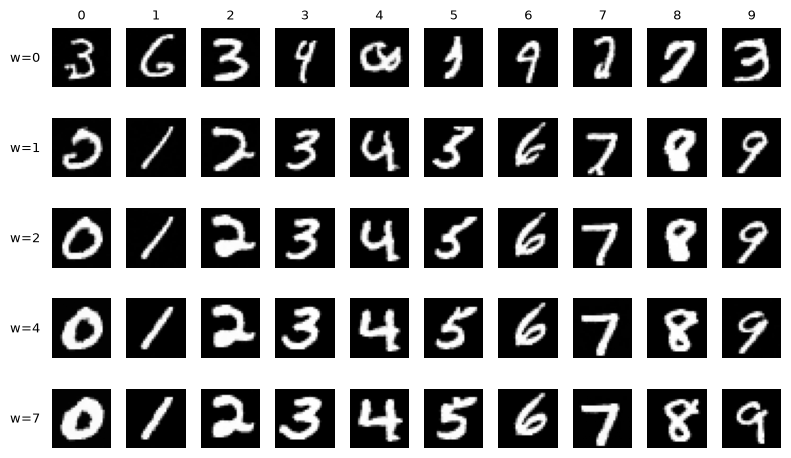

In [8]:
@torch.no_grad()
def guided_eps(net, x, t, y, w, counter=None):
    """ε_cfg = ε_u + w(ε_c − ε_u). При w=0 нужна только безусловная ветвь, при w=1 — только условная
    (1 NFE на сэмпл за шаг); иначе обе ветви одним батчем 2B (2 NFE на сэмпл за шаг)."""
    null = torch.full_like(y, NULL_CLASS)
    if w == 0:
        branches = {'uncond': x.shape[0]}
        eps = net(x, t, null)
    elif w == 1:
        branches = {'cond': x.shape[0]}
        eps = net(x, t, y)
    else:
        branches = {'cond': x.shape[0], 'uncond': x.shape[0]}
        eps_c, eps_u = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, null])).chunk(2)
        eps = eps_u + w * (eps_c - eps_u)
    if counter is not None:
        for k, v in branches.items():
            counter[k] += v
        counter['forward_calls'] += 1
    return eps


@torch.no_grad()
def ddpm_sample(net, sched, labels, w, x_start, generator, variance='posterior', counter=None):
    """Ancestral sampling DDPM: x_{t−1} = (x_t − β_t/sqrt(1−ā_t)·ε̂)/sqrt(α_t) + σ_t z,
    σ_t² = β̃_t ('posterior') или β_t ('beta'); на последнем шаге шум не добавляется."""
    net.eval()
    betas_, alphas_, abar_ = sched['betas'].tolist(), sched['alphas'].tolist(), sched['alpha_bars'].tolist()
    var_ = (sched['posterior_var'] if variance == 'posterior' else sched['betas']).tolist()
    x = x_start.to(DEVICE).clone()
    y = labels.to(DEVICE)
    for i in reversed(range(len(betas_))):
        t = torch.full((x.shape[0],), i, device=DEVICE, dtype=torch.long)
        eps = guided_eps(net, x, t, y, w, counter)
        x = (x - betas_[i] / math.sqrt(1 - abar_[i]) * eps) / math.sqrt(alphas_[i])
        if i > 0:
            x = x + math.sqrt(var_[i]) * torch.randn(x.shape, device=DEVICE, generator=generator)
    return x.clamp(-1, 1).cpu()


def save_grid(images, nrow, path, title=None):
    n = len(images); ncol = math.ceil(n / nrow)
    fig, axes = plt.subplots(nrow, ncol, figsize=(0.75 * ncol + 0.4, 0.75 * nrow + 0.4), squeeze=False)
    for k, ax in enumerate(axes.flat):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k, 0], cmap='gray', vmin=-1, vmax=1)
    if title:
        fig.suptitle(title, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=110)
    return fig


def cuda_sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


samples, sampling_stats = {}, []
for w in GUIDANCE_SCALES:
    counter = {'cond': 0, 'uncond': 0, 'forward_calls': 0}
    cuda_sync(); t0 = time.time()
    samples[w] = ddpm_sample(ema, SCHED, sample_labels, w, x_T, make_step_generator(), counter=counter)
    cuda_sync(); seconds = time.time() - t0
    nfe_per_sample = (counter['cond'] + counter['uncond']) / N_SAMPLES
    expected = T_STEPS if w in (0.0, 1.0) else 2 * T_STEPS
    assert nfe_per_sample == expected, (w, nfe_per_sample, expected)
    sampling_stats.append({'w': w, 'T': T_STEPS, 'nfe_per_sample': nfe_per_sample,
                           'nfe_cond_per_sample': counter['cond'] / N_SAMPLES,
                           'nfe_uncond_per_sample': counter['uncond'] / N_SAMPLES,
                           'batched_forward_calls': counter['forward_calls'],
                           'seconds': seconds, 'seconds_per_sample': seconds / N_SAMPLES})
    # строки — классы 0..9, столбцы — разные x_T
    save_grid(samples[w], 10, FIG_DIR / f'samples_w{w:g}.png', f'w={w:g}, NFE={nfe_per_sample:.0f}')
    plt.close('all')
    print(sampling_stats[-1])

torch.save({'samples': samples, 'labels': sample_labels, 'stats': sampling_stats,
            'checkpoint_step': TRAIN_STEPS, 'run_tag': RUN_TAG}, ARTIFACTS / 'samples_by_w.pt')
save_json('sampling_stats.json', sampling_stats)

# Сводная картинка: строка — w, столбцы — первый сэмпл каждого класса (одинаковый x_T по столбцу)
first_idx = torch.arange(10) * SAMPLES_PER_CLASS
fig, axes = plt.subplots(len(GUIDANCE_SCALES), 10, figsize=(8, 0.9 * len(GUIDANCE_SCALES) + 0.4))
for r, w in enumerate(GUIDANCE_SCALES):
    for c in range(10):
        axes[r, c].imshow(samples[w][first_idx[c], 0], cmap='gray', vmin=-1, vmax=1); axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(str(c), fontsize=9)
    axes[r, 0].text(-6, 14, f'w={w:g}', ha='right', va='center', fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / 'samples_by_w.png', dpi=120); plt.show()

#### Алгоритм генерации с classifier-free guidance — кратко

**Что есть на входе.** 100 случайных картинок-шумов $x_T$ (задание 6). Сами по себе они не принадлежат никакому классу: класс $y$ каждой назначен нами (по 10 на цифру). Плюс одно число $w$ — сила подсказки.

**$t$ и $w$ — разные вещи.**
- $t$ — степень зашумлённости, «время». За одну генерацию алгоритм сам проходит $t = 999 \to 0$.
- $w$ — насколько сильно тянуть картинку к заказанному классу. Задаётся нами один раз и **не меняется** всю генерацию.

**Один шаг** (на примере: шум №37, класс 5, текущий шаг $t$):

1. **Два вопроса к сети** про **текущую** картинку $x_t$:
   - условный: «шаг $t$, это должна быть пятёрка — где шум?» → $\varepsilon_c$ (карта 28×28);
   - безусловный: «шаг $t$, цифра неизвестна ($y=10$) — где шум?» → $\varepsilon_u$.
2. **Направление «к пятёрке»:** $\varepsilon_c - \varepsilon_u$ — что меняет в картинке знание о том, что это пятёрка. Эта карта считается **заново на каждом шаге**.
3. **Смешивание с $w$:** $\hat\varepsilon = \varepsilon_u + w(\varepsilon_c - \varepsilon_u)$.
   $w=0$ — подсказка не используется, $w=1$ — обычный условный ответ, $w>1$ — подсказка усилена в $w$ раз.
4. **Убрать немного шума** (это делает наш код, не сеть):
   $x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\hat\varepsilon\big) + \sigma_t z$,
   где $\sigma_t z$ — маленькая свежая «встряска» (кроме последнего шага), из генератора с фиксированным seed.
5. $t \to t-1$, повторить с п. 1 уже для новой, чуть более чистой картинки.

```
шум №37 (t=999) → [2 вопроса → смешать с w → убрать шум] → x_998 → ... (1000 раз) → готовая пятёрка (t=0)
```

Сеть только отвечает «где шум?»; смешивание, вычитание и уменьшение $t$ делает `ddpm_sample`. Исходной цифры нет: получается **новая** пятёрка, которой не было в датасете. $w$ сильнее всего влияет в начале (большие $t$), пока форма ещё не решена.

**Весь эксперимент.** Один и тот же набор из 100 шумов (и тех же встрясок) прогоняется 5 раз, при $w = 0, 1, 2, 4, 7$ → 500 готовых картинок. Отличается только $w$, поэтому разница между строками на `samples_by_w.png` — эффект силы подсказки:

| $w$ | что обычно получается |
|---|---|
| 0 | случайные цифры, класс игнорируется (попадание ~10%) |
| 1 | нужная цифра в большинстве случаев, почерк разнообразный |
| 2–4 | уверенные, чёткие цифры, но более однообразные |
| 7 | пересвеченные толстые штрихи, шаблонные цифры, артефакты |

**Зачем 100 шумов, а не один.** Из одного шума тоже можно получить любую цифру, меняя $y$ (шум задаёт «почерк», класс — «какую цифру писать»). Но одна картинка — это одна попытка, а не измерение. По 10 на класс нужны, чтобы честно посчитать долю попаданий в класс и разнообразие внутри класса (задание 8).

#### Что означает вывод задания 7

Для каждого значения $w$ печатается одна строка со статистикой генерации 100 картинок:

| поле | что означает |
|---|---|
| `w` | сила guidance (classifier-free guidance scale) |
| `T` | число шагов обратного процесса: генерация идёт от $t=T-1$ до $t=0$ |
| `nfe_per_sample` | **NFE (number of function evaluations) на одну картинку** — сколько раз за всю генерацию сеть «отвечала» за эту картинку. Сумма двух следующих полей |
| `nfe_cond_per_sample` | сколько из этих вызовов пришлось на **условную ветвь** (сети подан настоящий класс $y$) |
| `nfe_uncond_per_sample` | сколько пришлось на **безусловную ветвь** (подан $y=10$, «класс неизвестен») |
| `batched_forward_calls` | сколько раз сеть **реально запускалась** на GPU для всех 100 картинок сразу. При $w>1$ ответы с классом и без класса считаются одним запуском: 100 + 100 картинок склеиваются в батч из 200. Поэтому запусков $T$, хотя NFE $2T$ |
| `seconds` | реальное время генерации всех 100 картинок при этом $w$, в секундах |
| `seconds_per_sample` | то же время, делённое на 100: средняя цена одной картинки |

Сколько вызовов нужно, зависит от $w$. Формула CFG $\hat\varepsilon=\varepsilon_u+w(\varepsilon_c-\varepsilon_u)$ при $w=0$ превращается в $\varepsilon_u$, а при $w=1$ — в $\varepsilon_c$. В этих случаях второй ответ сети не нужен, и код его не запрашивает:

| $w$ | нужные ветви на каждом шаге | `nfe_cond` | `nfe_uncond` | `nfe_per_sample` | `batched_forward_calls` |
|---|---|---|---|---|---|
| 0 | только безусловная | 0 | $T$ | $T$ | $T$ |
| 1 | только условная | $T$ | 0 | $T$ | $T$ |
| 2, 4, 7 | обе | $T$ | $T$ | $2T$ | $T$ |

Поэтому генерация с guidance ($w>1$) вдвое дороже по NFE, и `seconds` при этих $w$ заметно больше. Код проверяет через `assert`, что NFE равно ровно $T$ или $2T$.

### Задание 8. Сохранение измерений генерации

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните метрики, изображения и точность проверяющего классификатора на test.

**Результат.** Проверяемое состояние «Сохранение измерений генерации» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните метрики, изображения и точность проверяющего классификатора на test» и его результат доступен следующему этапу.

**Измерения генерации**

- **Что делали**: показали все 500 сгенерированных картинок судье, посчитали точность по заказанному классу, уверенность p(y|x), равномерность классов H(pred) и разнообразие внутри класса (попарная RMS-разница пикселей), сравнили разнообразие с реальными test-цифрами.
- **Зачем**: численно показать компромисс fidelity/diversity при росте w.
- **Результат**: generation_metrics.json/.csv, generated_uint8.npz, guidance_tradeoff.png. Судья на test 0.987. Точность: w = 0 → 0.08 (угадывание, класс не подаётся), w = 1 → 0.95, w ≥ 2 → 1.00. Разнообразие: 0.321 (w = 1, ≈ реальным 0.312) → 0.295 → 0.273 → 0.261 (w = 7, на 16% ниже реального). Лучший компромисс — w ≈ 2.

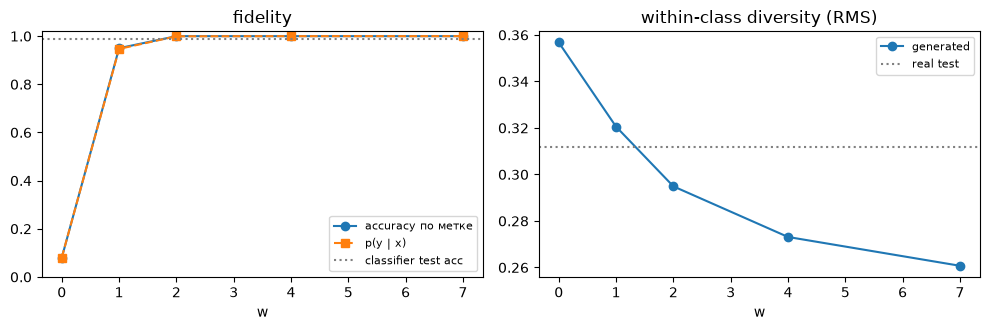

classifier test accuracy = 0.9870 (n=2000)
   w   NFE     sec    acc  p(y|x)  H(pred)    div
   0  1000    19.8  0.080   0.081    3.278  0.357
   1  1000    19.0  0.950   0.947    3.314  0.321
   2  2000    36.1  1.000   0.999    3.322  0.295
   4  2000    36.1  1.000   1.000    3.322  0.273
   7  2000    36.2  1.000   1.000    3.322  0.261
real test diversity = 0.312


In [9]:
def pairwise_rms(x):
    """Средняя попарная RMS-дистанция в пикселях [0, 1] — грубая мера разнообразия."""
    flat = ((x + 1) / 2).flatten(1)
    n = len(flat)
    if n < 2:
        return float('nan')
    return (torch.cdist(flat, flat).sum() / (n * (n - 1)) / math.sqrt(flat.shape[1])).item()


def within_class_diversity(x, labels):
    return float(np.mean([pairwise_rms(x[labels == c]) for c in range(10)]))


# Референс разнообразия: столько же реальных test-картинок на класс (только для сравнения, не для выбора)
real_ref_idx = torch.cat([(y_test == c).nonzero().flatten()[:SAMPLES_PER_CLASS] for c in range(10)])
real_diversity = within_class_diversity(X_test[real_ref_idx], y_test[real_ref_idx])

gen_eval, gen_rows = {}, []
for stats in sampling_stats:
    w = stats['w']
    probs = F.softmax(predict_logits(classifier, samples[w]), 1)
    pred = probs.argmax(1)
    target_p = probs[torch.arange(N_SAMPLES), sample_labels]
    pred_hist = torch.bincount(pred, minlength=10).float() / N_SAMPLES
    pred_entropy = max(0.0, -(pred_hist[pred_hist > 0] * pred_hist[pred_hist > 0].log2()).sum().item())
    per_class = [(pred[sample_labels == c] == c).float().mean().item() for c in range(10)]
    gen_eval[w] = {'probs': probs, 'pred': pred}
    gen_rows.append({'w': w, 'T': T_STEPS, 'nfe_per_sample': stats['nfe_per_sample'],
                     'seconds': round(stats['seconds'], 2),
                     'class_accuracy': (pred == sample_labels).float().mean().item(),  # при w=0 метка не подаётся → ~0.1
                     'mean_target_prob': target_p.mean().item(),
                     'mean_max_prob': probs.max(1).values.mean().item(),
                     'pred_class_entropy_bits': pred_entropy,                         # log2(10)=3.32 — все классы
                     'within_class_diversity': within_class_diversity(samples[w], sample_labels),
                     'real_test_diversity': real_diversity,
                     'per_class_accuracy': per_class})

generation_metrics = {'run_tag': RUN_TAG, 'checkpoint': str(DDPM_PATH), 'checkpoint_step': TRAIN_STEPS,
                      'n_samples_per_w': N_SAMPLES, 'samples_per_class': SAMPLES_PER_CLASS,
                      'classifier_checkpoint': str(CLASSIFIER_PATH),
                      'classifier_test_accuracy': cls_validation['test_accuracy'],
                      'classifier_n_test': cls_validation['n_test'],
                      'sampler': 'DDPM ancestral, sigma^2 = beta_tilde, EMA weights', 'rows': gen_rows}
save_json('generation_metrics.json', generation_metrics)
flat_keys = [k for k in gen_rows[0] if k != 'per_class_accuracy']
with open(ARTIFACTS / 'generation_metrics.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=flat_keys + ['classifier_test_accuracy'])
    writer.writeheader()
    for r in gen_rows:
        writer.writerow({**{k: r[k] for k in flat_keys}, 'classifier_test_accuracy': cls_validation['test_accuracy']})

# Сгенерированные изображения в uint8 — удобно для отчёта и lab 18
np.savez_compressed(ARTIFACTS / 'generated_uint8.npz', labels=sample_labels.numpy(),
                    **{f'w{w:g}': ((samples[w] + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).numpy()
                       for w in GUIDANCE_SCALES})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ws = [r['w'] for r in gen_rows]
ax[0].plot(ws, [r['class_accuracy'] for r in gen_rows], 'o-', label='accuracy по метке')
ax[0].plot(ws, [r['mean_target_prob'] for r in gen_rows], 's--', label='p(y | x)')
ax[0].axhline(cls_validation['test_accuracy'], color='gray', ls=':', label='classifier test acc')
ax[0].set_xlabel('w'); ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8); ax[0].set_title('fidelity')
ax[1].plot(ws, [r['within_class_diversity'] for r in gen_rows], 'o-', label='generated')
ax[1].axhline(real_diversity, color='gray', ls=':', label='real test')
ax[1].set_xlabel('w'); ax[1].legend(fontsize=8); ax[1].set_title('within-class diversity (RMS)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'guidance_tradeoff.png', dpi=120); plt.show()

print(f"classifier test accuracy = {cls_validation['test_accuracy']:.4f} (n={cls_validation['n_test']})")
print(f"{'w':>4} {'NFE':>5} {'sec':>7} {'acc':>6} {'p(y|x)':>7} {'H(pred)':>8} {'div':>6}")
for r in gen_rows:
    print(f"{r['w']:>4g} {r['nfe_per_sample']:>5.0f} {r['seconds']:>7.1f} {r['class_accuracy']:>6.3f} "
          f"{r['mean_target_prob']:>7.3f} {r['pred_class_entropy_bits']:>8.3f} {r['within_class_diversity']:>6.3f}")
print(f'real test diversity = {real_diversity:.3f}')

#### Что означает вывод задания 8

Каждая строка таблицы — 100 сгенерированных картинок (по 10 на цифру) при одном значении $w$. Их оценивает независимый классификатор-«судья» из задания 5.

| столбец | что означает |
|---|---|
| `w` | сила guidance (classifier-free guidance scale) |
| `NFE` | сколько вызовов сети понадобилось на одну картинку: $T$ при $w=0$ и $w=1$, $2T$ при $w>1$ (см. задание 7) |
| `sec` | время генерации всех 100 картинок при этом $w$, в секундах |
| `acc` | доля картинок, которые судья распознал как **заказанную** цифру. При $w=0$ класс модели не передаётся, поэтому ожидается уровень угадывания ≈ 0.1 |
| `p(y\|x)` | средняя уверенность судьи в заказанной цифре (вероятность класса $y$ по softmax), от 0 до 1. Мягкая версия `acc`: учитывает не только «угадал / нет», но и насколько уверенно |
| `H(pred)` | энтропия распределения цифр, которые **увидел** судья, в битах. Максимум $\log_2 10 = 3.322$ — все 10 цифр встречаются поровну; меньше — модель рисует одни цифры чаще других (часть классов «теряется») |
| `div` | разнообразие внутри класса: среднее попарное расстояние (RMS по пикселям в шкале [0, 1]) между картинками **одного** заказанного класса, усреднённое по 10 классам. Больше — цифры одного класса сильнее отличаются друг от друга |

Строки под таблицей:
- `classifier test accuracy` — точность самого судьи на реальных test-цифрах. Это «потолок» измерений: значения `acc` около него означают «не хуже, чем судья способен различить».
- `real test diversity` — тот же `div`, посчитанный на 100 **реальных** test-цифрах (по 10 на класс). Ориентир: насколько разнообразны живые почерки.

**Левый график — fidelity (верность классу).** По оси X — $w$, по оси Y — `acc` (синие кружки) и `p(y|x)` (оранжевые квадраты). Серый пунктир — точность судьи на реальном test. Показывает, насколько часто и уверенно генерация попадает в заказанную цифру при разной силе подсказки.

**Правый график — within-class diversity (разнообразие).** По оси X — $w$, по оси Y — `div` сгенерированных картинок (синие кружки). Серый пунктир — `real test diversity`. Показывает, насколько разными остаются цифры одного класса: точки ниже пунктира — модель рисует однообразнее, чем пишут живые люди.

Вместе два графика показывают **компромисс fidelity/diversity**: с ростом $w$ попадание в класс растёт (и выходит на плато), а разнообразие падает.

### Задание 9. Шумовая ошибка на разных временах

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps.

**Результат.** Проверяемое состояние «Шумовая ошибка на разных временах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps» и его результат доступен следующему этапу.

**Шумовая ошибка на разных t**

- **Что делали**: 500 test-картинок зашумили одним фиксированным шумом до t = 0, 20, 100, 250, 500, 749, 999 и измерили ошибку предсказания шума MSE(ε̂, ε) с подсказкой класса и без неё, плюс ошибку восстановления цифры x̂₀.
- **Зачем**: проверить предсказатель шума напрямую на отложенных картинках и увидеть, где подсказка класса реально помогает.
- **Результат**: noise_mse.json/.csv, noise_mse_by_t.png. Ошибка по шуму падает с t: 0.175 (t = 0) → 0.0105 (t = 500) → 0.0001 (t = 999), а ошибка восстановления цифры растёт: 0.000 → 0.124 → 0.422. Подсказка сильнее всего помогает на средних t: при t = 500 uncond − cond = 0.0027, выигрыш у 85% картинок; при малых t доля ≈ 0.54 (как монетка).

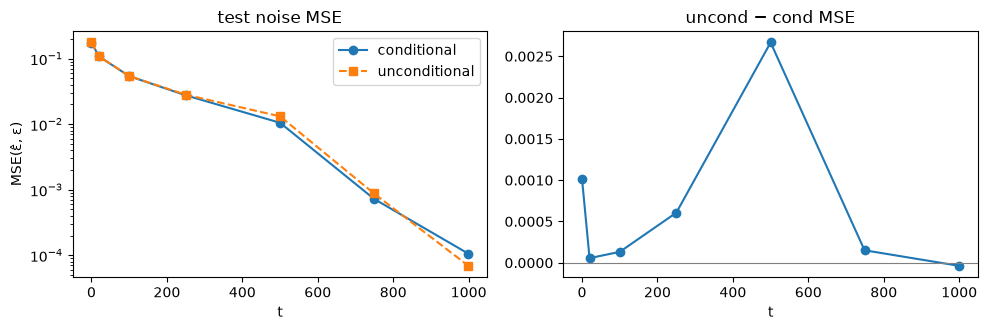

    t  sqrt(ā)     cond   uncond         Δ cond<unc   x0 MSE
    0   0.9999   0.1752   0.1762   0.00102    0.588   0.0000
   20   0.9969   0.1080   0.1080   0.00006    0.542   0.0007
  100   0.9461   0.0541   0.0542   0.00013    0.546   0.0063
  250   0.7221   0.0276   0.0282   0.00061    0.622   0.0252
  500   0.2789   0.0105   0.0132   0.00267    0.850   0.1242
  749   0.0579   0.0007   0.0009   0.00015    0.830   0.2108
  999   0.0064   0.0001   0.0001  -0.00004    0.024   0.4224


In [10]:
MSE_N = min(500, len(X_test))
EVAL_TIMESTEPS = sorted({int(round(f * (T_STEPS - 1))) for f in (0.0, 0.02, 0.1, 0.25, 0.5, 0.75, 1.0)})
mse_x0 = X_test[:MSE_N].to(DEVICE)
mse_y = y_test[:MSE_N].to(DEVICE)
mse_null = torch.full_like(mse_y, NULL_CLASS)
# Один и тот же шум для всех t и обеих ветвей: различия — только от t и условия
mse_noise = torch.randn(mse_x0.shape, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED + 7))

per_image_mse = {'cond': {}, 'uncond': {}}
noise_rows = []
ema.eval()
with torch.no_grad():
    for t_val in EVAL_TIMESTEPS:
        t = torch.full((MSE_N,), t_val, device=DEVICE, dtype=torch.long)
        xt = q_sample(mse_x0, t, mse_noise, SCHED_DEV)
        e_c, e_u = ema(xt, t, mse_y), ema(xt, t, mse_null)
        m_c = (e_c - mse_noise).pow(2).mean((1, 2, 3))
        m_u = (e_u - mse_noise).pow(2).mean((1, 2, 3))
        ab = alpha_bars[t_val].item()
        x0_hat = ((xt - math.sqrt(1 - ab) * e_c) / math.sqrt(ab)).clamp(-1, 1)
        per_image_mse['cond'][t_val], per_image_mse['uncond'][t_val] = m_c.cpu(), m_u.cpu()
        noise_rows.append({'t': t_val, 'alpha_bar': ab, 'signal_coef': math.sqrt(ab),
                           'cond_mse': m_c.mean().item(), 'uncond_mse': m_u.mean().item(),
                           'uncond_minus_cond': (m_u - m_c).mean().item(),
                           'cond_better_frac': (m_c < m_u).float().mean().item(),
                           'cond_mse_p95': m_c.quantile(0.95).item(),
                           'x0_mse_cond': (x0_hat - mse_x0).pow(2).mean().item(),
                           'zero_pred_mse': mse_noise.pow(2).mean().item()})  # ε̂=0 — тривиальный уровень

save_json('noise_mse.json', {'run_tag': RUN_TAG, 'n_images': MSE_N, 'mnist_test_indices': test_idx[:MSE_N].tolist(),
                             'noise_seed': SEED + 7, 'weights': 'ema', 'rows': noise_rows})
with open(ARTIFACTS / 'noise_mse.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(noise_rows[0].keys()))
    writer.writeheader(); writer.writerows(noise_rows)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ts = [r['t'] for r in noise_rows]
ax[0].plot(ts, [r['cond_mse'] for r in noise_rows], 'o-', label='conditional')
ax[0].plot(ts, [r['uncond_mse'] for r in noise_rows], 's--', label='unconditional')
ax[0].set_yscale('log'); ax[0].set_xlabel('t'); ax[0].set_ylabel('MSE(ε̂, ε)'); ax[0].legend(); ax[0].set_title('test noise MSE')
ax[1].plot(ts, [r['uncond_minus_cond'] for r in noise_rows], 'o-')
ax[1].axhline(0, color='gray', lw=0.8); ax[1].set_xlabel('t'); ax[1].set_title('uncond − cond MSE')
fig.tight_layout(); fig.savefig(FIG_DIR / 'noise_mse_by_t.png', dpi=120); plt.show()

print(f"{'t':>5} {'sqrt(ā)':>8} {'cond':>8} {'uncond':>8} {'Δ':>9} {'cond<unc':>8} {'x0 MSE':>8}")
for r in noise_rows:
    print(f"{r['t']:>5} {r['signal_coef']:>8.4f} {r['cond_mse']:>8.4f} {r['uncond_mse']:>8.4f} "
          f"{r['uncond_minus_cond']:>9.5f} {r['cond_better_frac']:>8.3f} {r['x0_mse_cond']:>8.4f}")

#### Что означает вывод задания 9

**Что измеряется.** 500 test-картинок зашумляются одним и тем же фиксированным шумом $\varepsilon$ до нескольких уровней $t$. Сеть (EMA-веса) спрашивают дважды: с настоящим классом (conditional) и с $y=10$ (unconditional). Настоящий шум известен, поэтому ошибка считается напрямую: $\mathrm{MSE}(\hat\varepsilon, \varepsilon)$. Ориентир: ответ «шума нет» ($\hat\varepsilon = 0$) дал бы MSE ≈ 1.

| столбец | что означает |
|---|---|
| `t` | уровень зашумления (0 — почти чистая цифра, 999 — почти чистый шум) |
| `sqrt(ā)` | $\sqrt{\bar\alpha_t}$ — сколько исходной цифры осталось в $x_t$ (1 — вся, 0 — ничего) |
| `cond` | средняя ошибка предсказания шума **с подсказкой класса**, $\mathrm{MSE}(\varepsilon_c, \varepsilon)$ |
| `uncond` | то же **без подсказки** ($y=10$), $\mathrm{MSE}(\varepsilon_u, \varepsilon)$ |
| `Δ` | `uncond − cond`. Больше нуля — подсказка класса уменьшила ошибку |
| `cond<unc` | доля из 500 картинок, у которых условная ошибка меньше безусловной (0.5 — подсказка не помогает, как монетка) |
| `x0 MSE` | ошибка восстановления **самой цифры**: $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon_c)/\sqrt{\bar\alpha_t}$, сравнение с настоящей $x_0$ в шкале [-1, 1] |

**Левый график — test noise MSE.** По оси X — $t$, по оси Y — `cond` и `uncond` (логарифмическая шкала).
Ошибка по шуму **падает** с ростом $t$, и это нормально: при большом $t$ картинка почти целиком состоит из шума, и угадать его легко. При малом $t$ шума добавлено чуть-чуть (доля $\sqrt{1-\bar\alpha_t}$ мала), и найти слабый «снег» поверх чёткой цифры трудно. Для самой цифры (`x0 MSE`) всё наоборот: при малом $t$ она видна, а при большом её почти не восстановить.

**Правый график — uncond − cond MSE.** По оси X — $t$, по оси Y — `Δ`, то есть выигрыш от подсказки класса.
- малые $t$: Δ ≈ 0 — цифра и так видна, класс ничего не добавляет;
- средние $t$: пик — цифра почти растворилась в шуме, и знание класса реально помогает отделить штрих от шума;
- $t$ около 999: Δ ≈ 0 — чистый шум, ответ «всё шум» верен для любого класса.

**Связь с CFG.** Guidance использует разность $\varepsilon_c - \varepsilon_u$. Правый график показывает, на каких шагах она существенна: в основном на средних $t$. Поэтому $w$ сильнее всего влияет в начале и середине генерации. А то, что `uncond` на всех $t$ близка к `cond`, означает, что безусловная ветвь обучилась (CFG dropout из задания 4 сработал).

### Задание 10. Худшие ошибки denoiser

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте реальные ошибки и пять худших test изображений.

**Результат.** Проверяемое состояние «Худшие ошибки denoiser» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте реальные ошибки и пять худших test изображений» и его результат доступен следующему этапу.

**Худшие ошибки**

- **Что делали**: усреднили условную ошибку по 7 значениям t для каждой из 500 test-картинок, взяли 5 худших и показали их (оригинал, x_t, x̂₀, карта ошибки). Отдельно нашли 5 сгенерированных картинок, в которых судья меньше всего видит заказанную цифру.
- **Зачем**: увидеть конкретные неудачи, а не только средние числа; материал для анализа ошибок.
- **Результат**: worst_errors.json, generation_failures.json, worst_denoiser_errors.png, generation_failures.png. Худшие test-цифры: 3, 2, 6, 5, 3; ошибка худшей в 1.99 раза выше медианы (0.054). Ошибка коррелирует с толщиной цифры (r = 0.63): жирные цифры даются труднее. Легче всего класс 1 (0.029), труднее всего 8 (0.066). Все 5 неудач генерации при w = 1: 4→2, 9→7, 6→1, 3→2, 1→7.

Что в столбцах
| Столбец | Что показано |
|---|---|
| **1. test #… y=…** | Оригинал, настоящая цифра. Её сеть не видит. |
| **2. x_t, t=250** | Эта цифра, зашумлённая до шага 250. Это и есть вход сети: цифру ещё видно, но много «снега». |
| **3. x̂₀ (cond)** | Восстановленная цифра. Сеть с подсказкой класса предсказала шум ε̂, мы вычли его из x_t и получили оценку исходной картинки. |
| **4. \|ε̂ − ε\|** | Карта ошибки по пикселям: разница между предсказанным шумом и настоящим. Тёмное — сеть угадала шум, светлое (жёлтое, оранжевое) — ошиблась. |


 Что видно на картинке

1. **Ошибки только на краях штрихов.** Фон почти чёрный: там сеть шум угадывает. А на границе «цифра / фон» сеть не знает точно, где кончается линия, поэтому ошибается.
2. **Восстановление «причёсывает» цифру.** Сравните столбцы 1 и 3: у тройки #464 рваные края и неровная толщина, а x̂₀ гладкий и аккуратный. Сеть рисует «типичную» тройку, а необычные детали конкретного почерка теряет. Вся ошибка как раз в этих деталях.
3. **Худшие — жирные и необычные цифры.** Корреляция ошибки с количеством «чернил» r = 0.63: у толстой цифры больше краёв, значит больше мест для ошибки. Плюс необычное написание: двойка #106 с петлёй, шестёрка #445 наклонена.

При поиске шума w не использовался. w нужен только при генерации

В нижних 5 картинка показаны сгенерированные цифры в которых судья классификатор меньшего всего видит заказанную цифру.

На примере w=1 y=4→2, p(y)=0.01:<br>
- w=1 — сила подсказки при генерации;<br>
- y=4→2 — заказали четвёрку, а судья увидел двойку;<br>
- p(y)=0.01 — уверенность судьи, что это заказанная цифра: всего 1%.



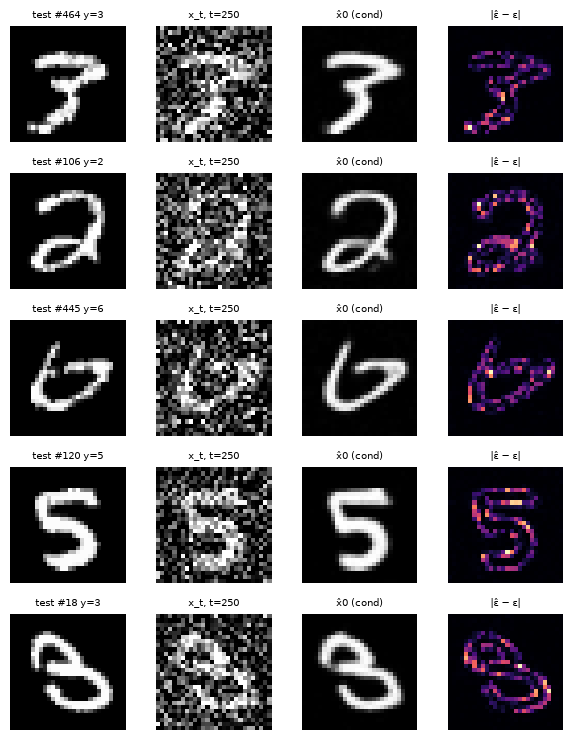

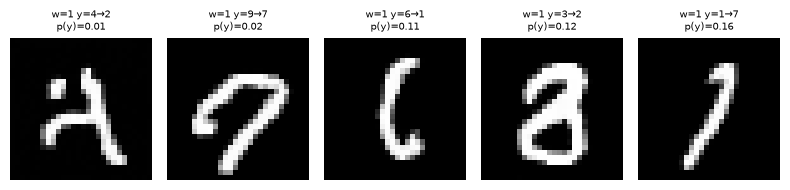

{'median': 0.0539, 'worst/median': 1.99, 'corr(MSE, ink)': 0.626}
{'rank': 1, 'subset_index': 464, 'mnist_test_index': 464, 'label': 3, 'mean_cond_mse': 0.1073, 'mean_uncond_mse': 0.106, 'ink_fraction': 0.1454, 'classifier_pred': 3, 'classifier_conf': 0.9996}
{'rank': 2, 'subset_index': 106, 'mnist_test_index': 106, 'label': 2, 'mean_cond_mse': 0.1023, 'mean_uncond_mse': 0.1022, 'ink_fraction': 0.1454, 'classifier_pred': 2, 'classifier_conf': 1.0}
{'rank': 3, 'subset_index': 445, 'mnist_test_index': 445, 'label': 6, 'mean_cond_mse': 0.0939, 'mean_uncond_mse': 0.0934, 'ink_fraction': 0.125, 'classifier_pred': 6, 'classifier_conf': 0.4662}
{'rank': 4, 'subset_index': 120, 'mnist_test_index': 120, 'label': 5, 'mean_cond_mse': 0.0935, 'mean_uncond_mse': 0.093, 'ink_fraction': 0.1862, 'classifier_pred': 5, 'classifier_conf': 1.0}
{'rank': 5, 'subset_index': 18, 'mnist_test_index': 18, 'label': 3, 'mean_cond_mse': 0.0931, 'mean_uncond_mse': 0.0923, 'ink_fraction': 0.1747, 'classifier_pred': 

In [11]:
N_WORST = 5
cond_matrix = torch.stack([per_image_mse['cond'][t] for t in EVAL_TIMESTEPS], 1)    # (MSE_N, n_t)
uncond_matrix = torch.stack([per_image_mse['uncond'][t] for t in EVAL_TIMESTEPS], 1)
mean_cond = cond_matrix.mean(1)
worst = mean_cond.topk(N_WORST).indices
real_probs = F.softmax(predict_logits(classifier, mse_x0.cpu()), 1)
ink = ((mse_x0.cpu() + 1) / 2 > 0.5).float().mean((1, 2, 3))  # доля «чернил» — толщина/размер цифры

VIS_T = EVAL_TIMESTEPS[len(EVAL_TIMESTEPS) // 2]
worst_records = []
fig, axes = plt.subplots(N_WORST, 4, figsize=(6, 1.5 * N_WORST))
with torch.no_grad():
    for r, i in enumerate(worst.tolist()):
        t = torch.full((1,), VIS_T, device=DEVICE, dtype=torch.long)
        xt = q_sample(mse_x0[i:i + 1], t, mse_noise[i:i + 1], SCHED_DEV)
        e_c = ema(xt, t, mse_y[i:i + 1])
        ab = alpha_bars[VIS_T].item()
        x0_hat = ((xt - math.sqrt(1 - ab) * e_c) / math.sqrt(ab)).clamp(-1, 1)
        err_map = (e_c - mse_noise[i:i + 1]).abs()
        panels = [mse_x0[i, 0], xt[0, 0].clamp(-1, 1), x0_hat[0, 0], err_map[0, 0]]
        titles = [f'test #{test_idx[i].item()} y={mse_y[i].item()}', f'x_t, t={VIS_T}', 'x̂0 (cond)', '|ε̂ − ε|']
        for c, (img, title) in enumerate(zip(panels, titles)):
            axes[r, c].imshow(img.cpu(), cmap='gray' if c < 3 else 'magma', **({'vmin': -1, 'vmax': 1} if c < 3 else {}))
            axes[r, c].set_title(title, fontsize=7); axes[r, c].axis('off')
        worst_records.append({'rank': r + 1, 'subset_index': i, 'mnist_test_index': test_idx[i].item(),
                              'label': mse_y[i].item(), 'mean_cond_mse': mean_cond[i].item(),
                              'mean_uncond_mse': uncond_matrix[i].mean().item(),
                              'cond_mse_by_t': dict(zip(map(str, EVAL_TIMESTEPS), cond_matrix[i].tolist())),
                              'ink_fraction': ink[i].item(),
                              'classifier_pred': int(real_probs[i].argmax()), 'classifier_conf': real_probs[i].max().item()})
fig.tight_layout(); fig.savefig(FIG_DIR / 'worst_denoiser_errors.png', dpi=120); plt.show()

per_class_mean = [mean_cond[mse_y.cpu() == c].mean().item() for c in range(10)]
worst_summary = {'run_tag': RUN_TAG, 'criterion': 'conditional MSE(ε̂, ε) averaged over EVAL_TIMESTEPS',
                 'timesteps': EVAL_TIMESTEPS, 'n_images': MSE_N,
                 'median_mean_cond_mse': mean_cond.median().item(),
                 'worst_to_median_ratio': (mean_cond[worst[0]] / mean_cond.median()).item(),
                 'corr_mse_ink': torch.corrcoef(torch.stack([mean_cond, ink]))[0, 1].item(),
                 'per_class_mean_cond_mse': per_class_mean, 'worst': worst_records}
save_json('worst_errors.json', worst_summary)

# Неудачи генерации: сэмплы с условием (w > 0) с наименьшей p(y | x) по проверяющему классификатору
cand = [(gen_eval[w]['probs'][k, sample_labels[k]].item(), w, k) for w in GUIDANCE_SCALES if w > 0 for k in range(N_SAMPLES)]
gen_failures = []
fig, axes = plt.subplots(1, N_WORST, figsize=(1.6 * N_WORST, 2))
for j, (p_target, w, k) in enumerate(sorted(cand)[:N_WORST]):
    pred = int(gen_eval[w]['pred'][k])
    gen_failures.append({'w': w, 'sample_index': k, 'label': int(sample_labels[k]), 'p_label': p_target,
                         'classifier_pred': pred, 'classifier_conf': gen_eval[w]['probs'][k, pred].item()})
    axes[j].imshow(samples[w][k, 0], cmap='gray', vmin=-1, vmax=1); axes[j].axis('off')
    axes[j].set_title(f'w={w:g} y={sample_labels[k].item()}→{pred}\np(y)={p_target:.2f}', fontsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / 'generation_failures.png', dpi=120); plt.show()
save_json('generation_failures.json', gen_failures)

print({'median': round(worst_summary['median_mean_cond_mse'], 4),
       'worst/median': round(worst_summary['worst_to_median_ratio'], 2),
       'corr(MSE, ink)': round(worst_summary['corr_mse_ink'], 3)})
for rec in worst_records:
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k != 'cond_mse_by_t'})
print('per-class mean cond MSE', [round(v, 4) for v in per_class_mean])
for g in gen_failures:
    print(g)

### Задание 11. Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

#### Гипотеза мини-исследования

**Контекст.** На каждом шаге обратного процесса DDPM после вычитания предсказанного шума к **всем пикселям** картинки добавляется небольшой свежий случайный шум — «встряска» $\sigma_t z$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\varepsilon\Big) + \sigma_t z,\qquad z \sim \mathcal N(0, I)$$

Встряска нужна, чтобы процесс оставался случайным и картинка не «сползала» к усреднённой размытой цифре. В статье DDPM (Ho et al., 2020) предложены два варианта её силы:
- $\sigma_t^2 = \tilde\beta_t = \beta_t\,\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}$ — «точная» дисперсия, чуть меньше (используется в основном эксперименте, задание 7);
- $\sigma_t^2 = \beta_t$ — верхняя граница, чуть больше.

**Гипотеза** (сформулирована до запуска). Если встряска сильнее ($\sigma_t^2 = \beta_t$), к концу генерации на картинках останется больше случайной «ряби». Тогда:
1. вырастет доля серых пикселей (яркость от 0.1 до 0.9 в шкале [0, 1]) — фон станет грязнее, края штрихов размытее;
2. упадёт уверенность проверяющего классификатора в заказанной цифре $p(y\mid x)$.

**Изменяемый фактор — только один:** формула $\sigma_t^2$ ($\tilde\beta_t \to \beta_t$).

**Зафиксировано всё остальное:** обученная модель (EMA-веса), те же 100 стартовых шумов $x_T$ и метки (задание 6), тот же seed генератора встрясок, $w = 2$ (выбран заранее, а не по результатам), $T = 1000$, тот же бюджет NFE = 2000 на картинку. Строка $\tilde\beta_t$ берётся из основного эксперимента без перегенерации. Test для выбора настройки не используется.

**Что измеряем:** точность и $p(y\mid x)$ по классификатору, долю серых пикселей, разнообразие внутри класса, время. Дополнительно — отношение $\beta_t/\tilde\beta_t$ по шагам: насколько две формулы вообще различаются.

**Творческий бонус: дисперсия обратного шага**

- **Что делали**: при w = 2 заменили силу встряски на каждом шаге σ_t² = β̃_t на σ_t² = β_t; модель, шумы, seed, классы и NFE = 2000 те же.
- **Зачем**: проверить гипотезу, что более сильная встряска даёт более грязные картинки и снижает уверенность судьи.
- **Результат**: bonus_variance.json и bonus_variance.png. Гипотеза не подтвердилась: точность 1.00 и p(y|x) 0.9994 в обоих вариантах, серых пикселей 0.0866 → 0.0871 (+0.5%, на уровне шума), разнообразие 0.295 в обоих. Причина: β_t/β̃_t ≈ 1 на большинстве шагов (медиана 1.001), заметно отличается только в самом конце (2.2 при t = 1), где шум и так ничтожен.

### Один шаг генерации полностью

1. Спрашиваем сеть с подсказкой и без, получаем ε_c и ε_u.
2. Смешиваем их: ε̂ = ε_u + w·(ε_c − ε_u).
3. **Вычитаем** часть ε̂ из x_t. Получаем «очищенную» картинку, это лучшая догадка сети о том, какой должна быть x_{t−1}.
4. **Встряска:** к очищенной картинке добавляем немного **нового** случайного шума:

   **x_{t−1} = очищенная картинка + σ_t · z**,

   где z — свежий случайный шум (из генератора задания 6), а σ_t — его сила.

5. Переходим к следующему шагу. На самом последнем шаге (t = 0) встряски нет, чтобы итоговая цифра вышла чистой.


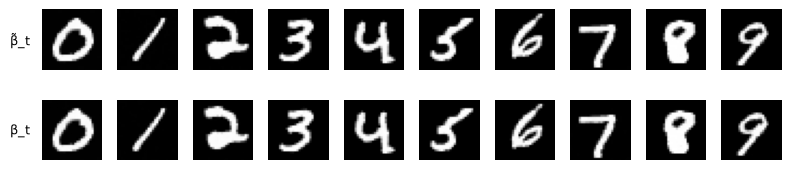

beta/beta_tilde at t=1: 2.2, median: 1.001
{'variance': 'beta_tilde (main)', 'w': 2.0, 'nfe_per_sample': 2000.0, 'seconds': 36.1402, 'class_accuracy': 1.0, 'mean_target_prob': 0.9994, 'gray_pixel_fraction': 0.0866, 'within_class_diversity': 0.2949}
{'variance': 'beta', 'w': 2.0, 'nfe_per_sample': 2000.0, 'seconds': 37.9322, 'class_accuracy': 1.0, 'mean_target_prob': 0.9994, 'gray_pixel_fraction': 0.0871, 'within_class_diversity': 0.2948}


In [12]:
# Гипотеза (сформулирована до запуска): дисперсия обратного шага σ_t² = β_t (верхняя граница из DDPM)
# добавляет больше шума, чем σ_t² = β̃_t, особенно на последних шагах, где β̃_t ≪ β_t. При тех же модели,
# x_T, генераторе z_t, w и NFE сэмплы станут «грязнее»: вырастет доля серых пикселей и упадёт p(y | x).
# Меняется один фактор — variance; w выбран заранее, test для выбора настройки не используется.
RUN_BONUS = True
BONUS_W = 2.0
assert BONUS_W in GUIDANCE_SCALES

if RUN_BONUS:
    def gray_fraction(x):
        u = (x + 1) / 2
        return ((u > 0.1) & (u < 0.9)).float().mean().item()

    def describe(x, variance, seconds, nfe):
        probs = F.softmax(predict_logits(classifier, x), 1)
        return {'variance': variance, 'w': BONUS_W, 'nfe_per_sample': nfe, 'seconds': seconds,
                'class_accuracy': (probs.argmax(1) == sample_labels).float().mean().item(),
                'mean_target_prob': probs[torch.arange(N_SAMPLES), sample_labels].mean().item(),
                'gray_pixel_fraction': gray_fraction(x),
                'within_class_diversity': within_class_diversity(x, sample_labels)}

    counter = {'cond': 0, 'uncond': 0, 'forward_calls': 0}
    cuda_sync(); t0 = time.time()
    x_beta = ddpm_sample(ema, SCHED, sample_labels, BONUS_W, x_T, make_step_generator(), variance='beta', counter=counter)
    cuda_sync(); beta_seconds = time.time() - t0
    main_stats = next(s for s in sampling_stats if s['w'] == BONUS_W)
    bonus_rows = [describe(samples[BONUS_W], 'beta_tilde (main)', main_stats['seconds'], main_stats['nfe_per_sample']),
                  describe(x_beta, 'beta', beta_seconds, (counter['cond'] + counter['uncond']) / N_SAMPLES)]
    assert bonus_rows[0]['nfe_per_sample'] == bonus_rows[1]['nfe_per_sample'], 'одинаковый бюджет NFE'
    tail_ratio = (SCHED['betas'][1:] / SCHED['posterior_var'][1:])
    save_json('bonus_variance.json', {'hypothesis': 'sigma^2=beta → больше серых пикселей и ниже p(y|x), чем beta_tilde',
                                      'fixed': 'model(EMA), x_T, step-noise seed, labels, w, T, NFE',
                                      'beta_over_beta_tilde_t1': tail_ratio[0].item(),
                                      'beta_over_beta_tilde_median': tail_ratio.median().item(),
                                      'rows': bonus_rows})

    fig, axes = plt.subplots(2, 10, figsize=(8, 2.2))
    for r, (x, name) in enumerate([(samples[BONUS_W], 'β̃_t'), (x_beta, 'β_t')]):
        for c in range(10):
            axes[r, c].imshow(x[first_idx[c], 0], cmap='gray', vmin=-1, vmax=1); axes[r, c].axis('off')
        axes[r, 0].text(-6, 14, name, ha='right', va='center', fontsize=9)
    fig.tight_layout(); fig.savefig(FIG_DIR / 'bonus_variance.png', dpi=120); plt.show()

    print(f'beta/beta_tilde at t=1: {tail_ratio[0].item():.1f}, median: {tail_ratio.median().item():.3f}')
    for row in bonus_rows:
        print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

In [13]:
import sys, platform
import matplotlib, torchvision

# Сводка прогона: версии, источники/лицензии, таблицы фактических метрик, список артефактов
run_info = {
    'run_tag': RUN_TAG, 'fast_dev_run': FAST_DEV_RUN, 'seed': SEED, 'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
    'versions': {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
                 'torchvision': torchvision.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__},
    'data': {'name': 'MNIST', 'source': 'torchvision.datasets.MNIST (yann.lecun.com mirror)', 'license': 'CC BY-SA 3.0',
             'train': f'first {N_TRAIN} of train', 'test': f'first {N_TEST} of test'},
    'models': {'ddpm': 'TinyDenoiser, trained from scratch here', 'classifier': 'DigitClassifier, trained from scratch here'},
    'config': {'T': T_STEPS, 'schedule': SCHEDULE_CONFIG, 'train': TRAIN_CONFIG, 'model': model.config,
               'guidance_scales': GUIDANCE_SCALES, 'samples_per_class': SAMPLES_PER_CLASS},
    'timing_seconds': {'ddpm_train': train_seconds, 'classifier_train': cls_seconds,
                       'sampling': {str(s['w']): s['seconds'] for s in sampling_stats},
                       'notebook_total': time.time() - NOTEBOOK_T0},
    'classifier_test_accuracy': cls_validation['test_accuracy'],
}
save_json('run_info.json', run_info)

for required in (DDPM_PATH, CLASSIFIER_PATH, ARTIFACTS / 'classifier_validation.json'):
    assert required.exists(), f'нет {required} — он нужен lab 18'

print(json.dumps(run_info['versions'], indent=1))
print(f"\nDDPM: {TRAIN_STEPS} шагов, {train_seconds / 60:.1f} мин, final cond/uncond loss "
      f"{train_summary['final_cond_loss']:.4f} / {train_summary['final_uncond_loss']:.4f}")
print(f"Классификатор: test acc {cls_validation['test_accuracy']:.4f} (n={cls_validation['n_test']})\n")
print(f"{'w':>4} {'NFE':>5} {'sec':>7} {'acc':>6} {'p(y|x)':>7} {'div':>6}")
for r in gen_rows:
    print(f"{r['w']:>4g} {r['nfe_per_sample']:>5.0f} {r['seconds']:>7.1f} {r['class_accuracy']:>6.3f} "
          f"{r['mean_target_prob']:>7.3f} {r['within_class_diversity']:>6.3f}")
print(f"\n{'t':>5} {'cond MSE':>9} {'uncond MSE':>11}")
for r in noise_rows:
    print(f"{r['t']:>5} {r['cond_mse']:>9.4f} {r['uncond_mse']:>11.4f}")
print('\nartifacts:')
for p in sorted(ARTIFACTS.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(ARTIFACTS)}  ({p.stat().st_size / 1024:.0f} KB)')

{
 "python": "3.12.1",
 "platform": "Windows-11-10.0.22631-SP0",
 "torch": "2.11.0+cu128",
 "torchvision": "0.26.0+cu128",
 "numpy": "2.5.3",
 "matplotlib": "3.11.2"
}

DDPM: 10000 шагов, 13.1 мин, final cond/uncond loss 0.0223 / 0.0232
Классификатор: test acc 0.9870 (n=2000)

   w   NFE     sec    acc  p(y|x)    div
   0  1000    19.8  0.080   0.081  0.357
   1  1000    19.0  0.950   0.947  0.321
   2  2000    36.1  1.000   0.999  0.295
   4  2000    36.1  1.000   1.000  0.273
   7  2000    36.2  1.000   1.000  0.261

    t  cond MSE  uncond MSE
    0    0.1752      0.1762
   20    0.1080      0.1080
  100    0.0541      0.0542
  250    0.0276      0.0282
  500    0.0105      0.0132
  749    0.0007      0.0009
  999    0.0001      0.0001

artifacts:
  bonus_variance.json  (1 KB)
  checkpoints\ddpm_last.pt  (36553 KB)
  classifier.pt  (1842 KB)
  classifier_validation.json  (3 KB)
  ddpm.pt  (36508 KB)
  denoiser_shapes.json  (1 KB)
  figures\bonus_variance.png  (45 KB)
  figures\forwa

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.